# subset_final_snakemake — all_batches (meningioma) — FINAL clean pipeline

Single-parameter final UMAP + Leiden per modality, locked from the exploration sweep: **HCG n_pc=20 k=25**, **Hi-C n_pc=5 k=25**, **GCH n_pc=9 k=25**, Leiden res 0.2, Harmony by `group`. Produces per-modality UMAPs, 5-panel comparisons (sample · own-Leiden · HCG-Leiden · CNA group · group), a joint embedding, and saves `tables/final_metadata.tsv` + `final_umap_*.tsv` + `annotation/*_cells.txt` for downstream analysis. Palettes match the CNA notebook. Run the CNA notebook first (for `cna_approach3_clusters.txt`).

In [1]:
# §1 Setup — FINAL single-parameter pipeline (params locked from the exploration sweep)
Sys.setenv(RETICULATE_PYTHON = "/projects/b1198/epifluidlab/yoshii/software/conda/envs/scnomehic/bin/python")
suppressPackageStartupMessages({
  library(umap); library(impute); library(igraph); library(cccd)
  library(rhdf5); library(RColorBrewer); library(harmony)
  library(dplyr); library(tidyr); library(tibble); library(ggplot2); library(patchwork)
})
set.seed(42)
WORKDIR <- "/gpfs/projects/b1198/epifluidlab/yoshii/meningioma_scnomehic/snakemake"
OUT_DIR <- file.path(WORKDIR, "subset_clustering", "250kb", "all_batches")
OUT_TAB <- file.path(OUT_DIR, "tables"); OUT_FIG <- file.path(OUT_DIR, "figures")
ANN_DIR <- file.path(OUT_DIR, "annotation")
for (d in c(OUT_TAB, OUT_FIG, ANN_DIR)) dir.create(d, recursive = TRUE, showWarnings = FALSE)
setwd(WORKDIR); par(bg = "white")

# ---- frozen embeddings ------------------------------------------------------
# UMAP layouts are NOT portable across R builds: the same code and inputs give a
# different picture under a different R/BLAS, while the Leiden labels stay the
# same. So each embedding is computed once, saved at full precision, and reused.
# Delete tables/frozen/ to recompute everything from scratch.
FROZEN <- file.path(OUT_TAB, "frozen")
dir.create(FROZEN, recursive = TRUE, showWarnings = FALSE)
freeze <- function(name, expr) {
  f <- file.path(FROZEN, paste0(name, ".rds"))
  if (file.exists(f)) {
    cat("  [frozen] ", name, "\n", sep = "")
    readRDS(f)
  } else {
    v <- force(expr)
    saveRDS(v, f)
    cat("  [computed + frozen] ", name, "\n", sep = "")
    v
  }
}


# LOCKED final parameters (from exploration §4e/§5e/§6e)
HCG_NPC <- 20; HCG_K <- 25
HIC_NPC <- 5;  HIC_K <- 25
GCH_NPC <- 9;  GCH_K <- 25
LEIDEN_RES <- 0.2
JOINT_K <- 25; JOINT_RES <- 0.2   # Leiden on the joint embedding (for tumor/macrophage annotation)
# CNA sub-clone palette (grey normal + purple/magenta/olive/gold) — matches the CNA notebook.
CLONE_PAL <- c("1"="#BBBBBB","2"="#7570B3","3"="#E7298A","4"="#66A61E","5"="#E6AB02")
.tf <- theme_void(base_size = 10) + theme(plot.title = element_text(size = 10, hjust = .5),
        legend.position = "right",
        axis.line.x.bottom = element_line(colour = "grey30", linewidth = .3),
        axis.line.y.left   = element_line(colour = "grey30", linewidth = .3))
cat("FINAL params — HCG npc", HCG_NPC, "k", HCG_K, "| HiC npc", HIC_NPC, "k", HIC_K,
    "| GCH npc", GCH_NPC, "k", GCH_K, "| res", LEIDEN_RES, "| Harmony by group\n")

FINAL params — HCG npc 20 k 25 | HiC npc 5 k 25 | GCH npc 9 k 25 | res 0.2 | Harmony by group


In [2]:
# §2 Helpers (from sc_nomehic subset_final_snakemake_exploration §3)
perform_imputation <- function(m, k = 10)
  suppressWarnings(suppressMessages(impute.knn(m, k = k, maxp = "p")$data))

quantile_normalize <- function(M) {  # per-column (cell) quantile normalize, NA-aware
  nC <- ncol(M); mx <- max(colSums(!is.na(M)))
  S <- matrix(NA_real_, mx, nC)
  for (i in seq_len(nC)) { v <- sort(M[!is.na(M[, i]), i]); S[seq_along(v), i] <- v }
  rm_ <- rowMeans(S, na.rm = TRUE)
  out <- matrix(NA_real_, nrow(M), nC, dimnames = dimnames(M))
  for (i in seq_len(nC)) { idx <- !is.na(M[, i]); out[idx, i] <- rm_[rank(M[idx, i], ties.method = "average")] }
  out
}

# SVD on scaled cells x features; drops non-finite (NA / zero-variance) columns
# so sparse sets don't hit 'infinite or missing values in x'.
svd_u <- function(cells_x_feat, n = 20) {
  sc <- scale(cells_x_feat); sc <- sc[, colSums(!is.finite(sc)) == 0, drop = FALSE]
  u <- svd(sc)$u; rownames(u) <- rownames(cells_x_feat); u
}

build_knn_graph <- function(emb, n_pc, k) {
  ng <- min(n_pc, ncol(emb)); g <- cccd::nng(emb[, seq_len(ng), drop = FALSE], k = k)
  if ("weight" %in% igraph::edge_attr_names(g)) g <- igraph::delete_edge_attr(g, "weight")
  igraph::as.undirected(g, mode = "collapse")
}
run_leiden <- function(emb, n_pc = 10, k = 25, resolution = 0.2) {
  com <- igraph::cluster_leiden(build_knn_graph(emb, n_pc, k),
          objective_function = "modularity", resolution_parameter = resolution, n_iterations = 5)
  as.integer(igraph::membership(com))
}

# Leiden cluster-count for every (n_pc, k) at fixed resolution -> tidy data.frame.
sweep_clusters <- function(emb, npc = SWEEP_NPC, ks = SWEEP_K, resolution = SWEEP_RES) {
  grid <- expand.grid(n_pc = npc, k = ks)
  grid$n_clusters <- vapply(seq_len(nrow(grid)), function(i)
    length(unique(run_leiden(emb, grid$n_pc[i], grid$k[i], resolution))), integer(1))
  grid
}

# Distinct palettes: Leiden = Dark2 (greens/orange/purple, recycled for many
# clusters); batch = blue/red/black — hues Dark2 doesn't use, so the two
# colorings are clearly different families at a glance.
pal_leiden <- function(n) grDevices::colorRampPalette(RColorBrewer::brewer.pal(8, "Dark2"))(max(n, 1))
# 4-group palette: patient1 = blue shades, patient2 = red shades (sample by hue
# family, plate by light/dark). Distinct from Dark2 (Leiden) and Set1 (HCG).
LIBRARY_PAL <- c(patient1_plate1 = "#1F78B4", patient1_plate2 = "#A6CEE3",
               patient2_plate1 = "#E31A1C", patient2_plate2 = "#FB9A99", other = "grey70")
# sample palette (patient1/2) — teal/orange, a DISTINCT family from group's blue/red.
# Consistent with the CNA notebook's patient_color.
PATIENT_PAL <- c(patient1 = "#1B9E77", patient2 = "#D95F02", other = "grey70")
# original sequencing batches (batch1/2/3) palette — Set2, distinct from above.
SEQBATCH_PAL <- c(batch1 = "#66C2A5", batch2 = "#FC8D62", batch3 = "#8DA0CB", other = "grey70")
# selected-HCG cluster palette (Set1) — distinct from Dark2 (own Leiden) and from
# batch; used wherever cells are colored by the chosen HCG clustering.
pal_hcg <- function(n) grDevices::colorRampPalette(RColorBrewer::brewer.pal(9, "Set1"))(max(n, 1))

# Grid figure: one row per n_pc, columns grouped by k. For each (n_pc, k) combo
# compute ONE UMAP (on n_pc PCs, n_neighbors = k) and show it colored by Leiden
# cluster and by batch. If `annot` (a named factor of per-cell labels, e.g. the
# selected HCG clustering) is given, a 3rd panel per combo colors by it (Set1).
# Both n_pc (rows, distinct layouts) and k (column groups) vary; resolution fixed.
# Each panel gets bottom + left axis lines (L-shape) so panels are separated.
sweep_umap_panels <- function(emb, meta, name, npc = SWEEP_NPC, ks = SWEEP_K,
                              resolution = SWEEP_RES, annot = NULL, annot_name = "HCG") {
  th <- theme_void(base_size = 8) + theme(
    plot.title       = element_text(size = 7, hjust = .5),
    legend.position  = "none",
    axis.line.x.bottom = element_line(colour = "grey30", linewidth = .3),
    axis.line.y.left   = element_line(colour = "grey30", linewidth = .3),
    plot.margin      = margin(4, 6, 4, 4))
  per_k <- if (is.null(annot)) 2L else 3L
  panels <- list()
  for (np in npc) {
    ng <- min(np, ncol(emb))
    for (kk in ks) {
      nn <- max(2, min(kk, nrow(emb) - 1))
      set.seed(42)
      lay <- umap(as.matrix(emb[, seq_len(ng), drop = FALSE]), n_neighbors = nn)$layout
      cl  <- factor(run_leiden(emb, np, kk, resolution))
      df  <- data.frame(UMAP1 = lay[, 1], UMAP2 = lay[, 2], cl = cl,
                        library = meta[rownames(emb), "library"])
      panels[[length(panels) + 1]] <- ggplot(df, aes(UMAP1, UMAP2, colour = cl)) +
        geom_point(size = .5, alpha = .8) + scale_colour_manual(values = pal_leiden(nlevels(cl))) +
        ggtitle(sprintf("npc%d k%d  %dcl", np, kk, nlevels(cl))) + th
      panels[[length(panels) + 1]] <- ggplot(df, aes(UMAP1, UMAP2, colour = library)) +
        geom_point(size = .5, alpha = .8) + scale_colour_manual(values = LIBRARY_PAL) +
        ggtitle(sprintf("npc%d k%d  library", np, kk)) + th
      if (!is.null(annot)) {
        df$annot <- factor(annot[rownames(emb)])
        panels[[length(panels) + 1]] <- ggplot(df, aes(UMAP1, UMAP2, colour = annot)) +
          geom_point(size = .5, alpha = .8) +
          scale_colour_manual(values = pal_hcg(nlevels(df$annot)), na.value = "grey85") +
          ggtitle(sprintf("npc%d k%d  %s", np, kk, annot_name)) + th
      }
    }
  }
  wrap_plots(panels, ncol = per_k * length(ks))   # per k: [Leiden | batch] (+ annot)
}

# Adjusted Rand Index (no extra package).
adj_rand <- function(a, b) {
  tab <- table(a, b); n <- sum(tab)
  if (n < 2) return(NA_real_)
  cc <- function(x) sum(x * (x - 1) / 2)
  idx <- cc(as.vector(tab)); e <- cc(rowSums(tab)) * cc(colSums(tab)) / (n * (n - 1) / 2)
  m   <- (cc(rowSums(tab)) + cc(colSums(tab))) / 2
  if (m - e == 0) return(0)
  (idx - e) / (m - e)
}

# For each (n_pc, k): ARI between Leiden(emb) and reference clustering `ref`
# (named vector), on the shared cells. Returns the grid sorted by ARI desc.
best_match <- function(emb, ref, npc = SWEEP_NPC, ks = SWEEP_K, resolution = SWEEP_RES) {
  common <- intersect(rownames(emb), names(ref))
  grid <- expand.grid(n_pc = npc, k = ks)
  grid$ARI <- NA_real_; grid$n_clusters <- NA_integer_
  for (i in seq_len(nrow(grid))) {
    cl <- run_leiden(emb, grid$n_pc[i], grid$k[i], resolution); names(cl) <- rownames(emb)
    grid$ARI[i] <- adj_rand(cl[common], ref[common]); grid$n_clusters[i] <- length(unique(cl))
  }
  grid[order(-grid$ARI), ]
}

# Single (n_pc, k) UMAP shown 3 ways: own Leiden | reference (HCG) | batch.
plot_one_combo <- function(emb, meta, np, kk, ref, name, resolution = SWEEP_RES) {
  th <- theme_void(base_size = 10) + theme(plot.title = element_text(size = 10, hjust = .5),
          legend.position = "right",
          axis.line.x.bottom = element_line(colour = "grey30", linewidth = .3),
          axis.line.y.left   = element_line(colour = "grey30", linewidth = .3))
  nn <- max(2, min(kk, nrow(emb) - 1)); set.seed(42)
  lay <- umap(as.matrix(emb[, seq_len(min(np, ncol(emb))), drop = FALSE]), n_neighbors = nn)$layout
  cl  <- factor(run_leiden(emb, np, kk, resolution))
  df  <- data.frame(UMAP1 = lay[, 1], UMAP2 = lay[, 2], cl = cl,
                    hcg = factor(ref[rownames(emb)]), library = meta[rownames(emb), "library"])
  (ggplot(df, aes(UMAP1, UMAP2, colour = cl)) + geom_point(size = .9, alpha = .85) +
     scale_colour_manual(values = pal_leiden(nlevels(cl))) +
     ggtitle(sprintf("%s npc%d k%d  Leiden (%dcl)", name, np, kk, nlevels(cl))) + th) |
  (ggplot(df, aes(UMAP1, UMAP2, colour = hcg)) + geom_point(size = .9, alpha = .85) +
     scale_colour_manual(values = pal_hcg(nlevels(df$hcg)), na.value = "grey85") +
     ggtitle("HCG clusters") + th) |
  (ggplot(df, aes(UMAP1, UMAP2, colour = library)) + geom_point(size = .9, alpha = .85) +
     scale_colour_manual(values = LIBRARY_PAL) + ggtitle("library") + th)
}

In [3]:
# §3 Metadata — sample / plate / group (4-way), replacing batch1/2/3
qc <- read.table(file.path(WORKDIR, "QC", "meningioma_qc_summary.txt"),
                 header = TRUE, sep = "\t", stringsAsFactors = FALSE, comment.char = "")
passed <- readLines(file.path(WORKDIR, "QC", "meningioma_passed_hicusable.txt"))
submetadata <- qc[qc$prefix %in% passed, , drop = FALSE]
rownames(submetadata) <- submetadata$prefix
submetadata$cell <- submetadata$prefix

# patient1 = MY_ (plate1 = MY_1..24, plate2 = MY_25..48);
# patient2 = NU04113 (plate1 = NU04113_<n>_S, plate2 = NU04113_scNOMe_HiC_p2_*)
assign_group <- function(p) {
  if (grepl("^NU04113_scNOMe_HiC_p2_", p)) return("patient2_plate2")
  if (grepl("^NU04113_", p))               return("patient2_plate1")
  if (grepl("^MY_", p)) {
    n <- suppressWarnings(as.integer(sub("^MY_([0-9]+)_.*", "\\1", p)))
    return(if (!is.na(n) && n <= 24) "patient1_plate1" else "patient1_plate2")
  }
  "other"
}
submetadata$library  <- vapply(submetadata$prefix, assign_group, character(1))
submetadata$patient <- sub("_plate.*", "", submetadata$library)   # patient1 / patient2
submetadata$plate  <- sub(".*_",      "", submetadata$library)   # plate1 / plate2
# original sequencing batches kept too: batch1 = MY (both plates),
# batch2 = NU04113_<n>_S, batch3 = NU04113_scNOMe_HiC_p2
submetadata$seqbatch <- ifelse(grepl("^NU04113_scNOMe_HiC_p2_", submetadata$prefix), "batch3",
                        ifelse(grepl("^NU04113_", submetadata$prefix), "batch2",
                        ifelse(grepl("^MY_", submetadata$prefix), "batch1", "other")))
LIBRARY_ORDER <- c("patient1_plate1", "patient1_plate2", "patient2_plate1", "patient2_plate2")
cat("Cells:", nrow(submetadata), "\n"); print(table(submetadata$library))
cat("seqbatch:\n"); print(table(submetadata$seqbatch))

Cells: 292 



patient1_plate1 patient1_plate2 patient2_plate1 patient2_plate2 
             70              80              67              75 


seqbatch:



batch1 batch2 batch3 
   150     67     75 


## §4 HCG methylation — load → impute → SVD → Harmony(group) → UMAP + Leiden

In [4]:
# §4 HCG methylation -> impute -> SVD -> Harmony(by batch, top-20 PCs)
hcg <- data.matrix(read.table(gzfile(file.path(WORKDIR, "QC", "methylation_matrices",
        "methylation_matrix_HCG_250kb.tsv.gz")), header = TRUE, sep = "\t",
        row.names = 1, check.names = FALSE, na.strings = c("NA", "", "NaN")))
hcg <- hcg[intersect(rownames(hcg), submetadata$cell), , drop = FALSE]
hcg <- hcg[, colSums(is.na(hcg)) < 0.8 * nrow(hcg), drop = FALSE]
hcg <- perform_imputation(hcg, 10)
HCG.svd <- svd_u(hcg, 20)
meta_h <- submetadata[rownames(HCG.svd), ]
set.seed(42)
HCG.harm <- freeze("HCG_harm", RunHarmony(HCG.svd[, 1:min(20, ncol(HCG.svd))], meta_h, vars_use = "library", verbose = FALSE))
rownames(HCG.harm) <- rownames(HCG.svd)
cat("HCG: cells x SVD =", dim(HCG.svd), "| harmony dims =", dim(HCG.harm), "\n")

  [frozen] HCG_harm


HCG: cells x SVD = 292 292 | harmony dims = 292 20 


  [frozen] HCG_umap


Warning message:
“The `resolution_parameter` argument of `cluster_leiden()` is deprecated as of
igraph 2.1.0.
ℹ Please use the `resolution` argument instead.”


Warning message:
“`as.undirected()` was deprecated in igraph 2.1.0.
ℹ Please use `as_undirected()` instead.”


HCG Leiden: 5 clusters


hcg_cluster
  1   2   3   4   5 
 34  42  42 108  66 


Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'HCG — patient' in 'mbcsToSbcs': dot substituted for <e2>”


... (40 outputs left out)

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'HCG — Leiden npc20 k25 (5cl)' in 'mbcsToSbcs': dot substituted for <94>”


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'HCG — library' in 'mbcsToSbcs': dot substituted for <e2>”


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'HCG — library' in 'mbcsToSbcs': dot substituted for <80>”


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'HCG — library' in 'mbcsToSbcs': dot substituted for <94>”


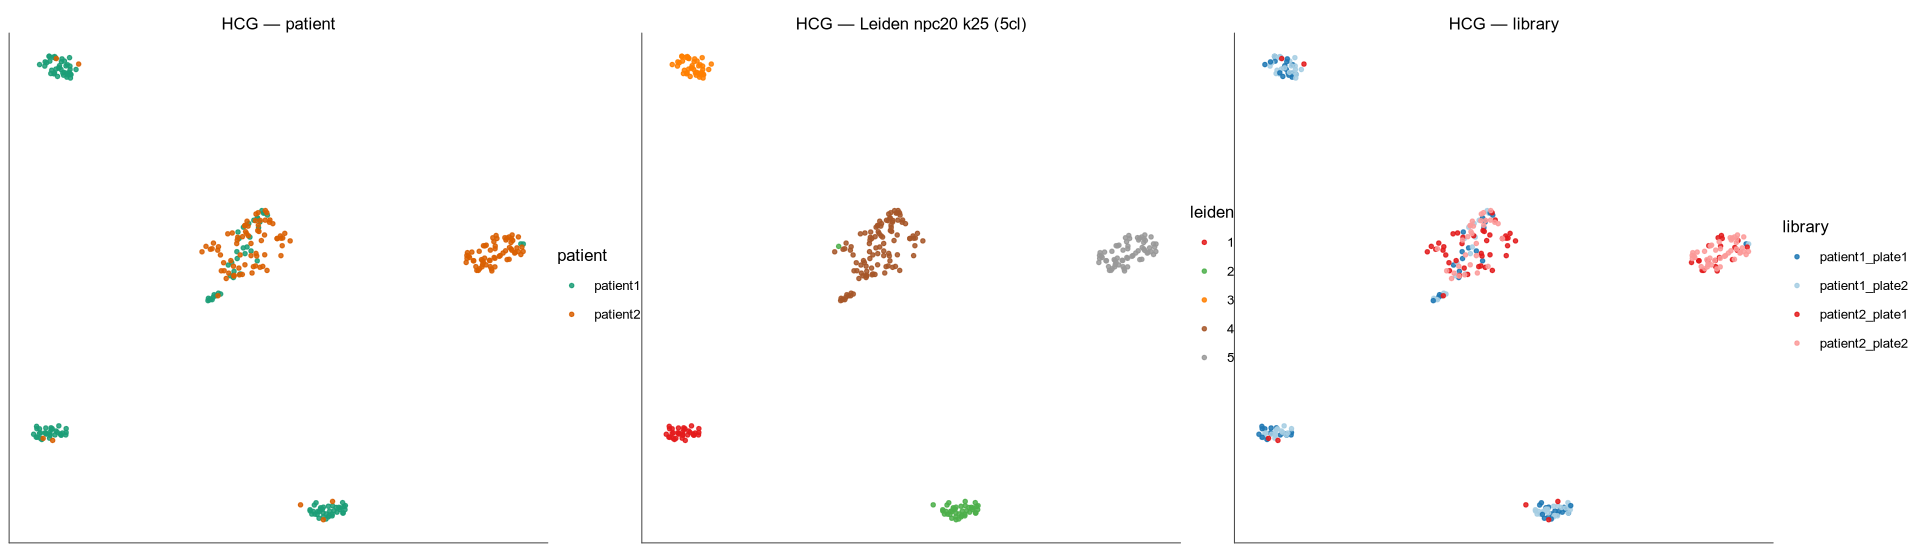

In [5]:
# §4b HCG final: UMAP + Leiden at n_pc=20, k=25, res=0.2 -> hcg_cluster (THE HCG label)
set.seed(42)
HCG.umap <- freeze("HCG_umap", umap(as.matrix(HCG.harm[, 1:min(HCG_NPC, ncol(HCG.harm)), drop = FALSE]),
                 n_neighbors = max(2, min(HCG_K, nrow(HCG.harm) - 1)))$layout)
hcg_cluster <- setNames(run_leiden(HCG.harm, HCG_NPC, HCG_K, LEIDEN_RES), rownames(HCG.harm))
submetadata$hcg_cluster <- NA_integer_
submetadata[names(hcg_cluster), "hcg_cluster"] <- as.integer(hcg_cluster)
cat("HCG Leiden:", length(unique(hcg_cluster)), "clusters\n"); print(table(hcg_cluster))
dfh <- data.frame(UMAP1 = HCG.umap[,1], UMAP2 = HCG.umap[,2],
                  patient = submetadata[rownames(HCG.umap), "patient"],
                  leiden = factor(hcg_cluster[rownames(HCG.umap)]),
                  library  = submetadata[rownames(HCG.umap), "library"])
options(repr.plot.width = 16, repr.plot.height = 4.6)
pH <- (ggplot(dfh, aes(UMAP1,UMAP2,colour=patient)) + geom_point(size=.9,alpha=.85) +
         scale_colour_manual(values=PATIENT_PAL) + ggtitle("HCG — patient") + .tf) |
      (ggplot(dfh, aes(UMAP1,UMAP2,colour=leiden)) + geom_point(size=.9,alpha=.85) +
         scale_colour_manual(values=pal_hcg(nlevels(dfh$leiden))) +
         ggtitle(sprintf("HCG — Leiden npc%d k%d (%dcl)",HCG_NPC,HCG_K,nlevels(dfh$leiden))) + .tf) |
      (ggplot(dfh, aes(UMAP1,UMAP2,colour=library)) + geom_point(size=.9,alpha=.85) +
         scale_colour_manual(values=LIBRARY_PAL) + ggtitle("HCG — library") + .tf)
ggsave(file.path(OUT_FIG, "final_hcg.pdf"), pH, width=16, height=4.6); pH

## §5 Hi-C — load embedding → Harmony(group) → UMAP + Leiden

In [6]:
# §5 Hi-C embedding -> Harmony(by batch, top-20 PCs)
hic_h5 <- file.path(WORKDIR, "06.hiccluster_snakemake",
                    "hicluster_250kb_embed_dir_all3",
                    "all_merged.pad1_std1_rp0.5_sqrtvc.svd20.hdf5")
hic_ord <- file.path(WORKDIR, "06.hiccluster_snakemake",
                     "hicluster_250kb_chr1_impute_file_list_all3.txt")
hic <- t(h5read(hic_h5, "/data"))
ind <- sub("_chr\\S+", "", sub("\\S+chr1/", "", readLines(hic_ord), perl = TRUE), perl = TRUE)
stopifnot(length(ind) == nrow(hic)); rownames(hic) <- ind
hic <- hic[intersect(rownames(hic), submetadata$cell), , drop = FALSE]
meta_hic <- submetadata[rownames(hic), ]
set.seed(42)
HIC.harm <- freeze("HIC_harm", RunHarmony(hic[, 1:min(20, ncol(hic))], meta_hic, vars_use = "library", verbose = FALSE))
rownames(HIC.harm) <- rownames(hic)
cat("HiC: cells x PCs =", dim(hic), "| harmony dims =", dim(HIC.harm), "\n")

  [frozen] HIC_harm


HiC: cells x PCs = 292 20 | harmony dims = 292 20 


  [frozen] HIC_umap


HiC Leiden: 2 clusters


hic_cluster
  1   2 
188 104 


Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'HiC — patient' in 'mbcsToSbcs': dot substituted for <e2>”


Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'HiC — patient' in 'mbcsToSbcs': dot substituted for <80>”


Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'HiC — patient' in 'mbcsToSbcs': dot substituted for <94>”


... (38 outputs left out)

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'HiC — Leiden npc5 k25 (2cl)' in 'mbcsToSbcs': dot substituted for <94>”


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'HiC — library' in 'mbcsToSbcs': dot substituted for <e2>”


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'HiC — library' in 'mbcsToSbcs': dot substituted for <80>”


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'HiC — library' in 'mbcsToSbcs': dot substituted for <94>”


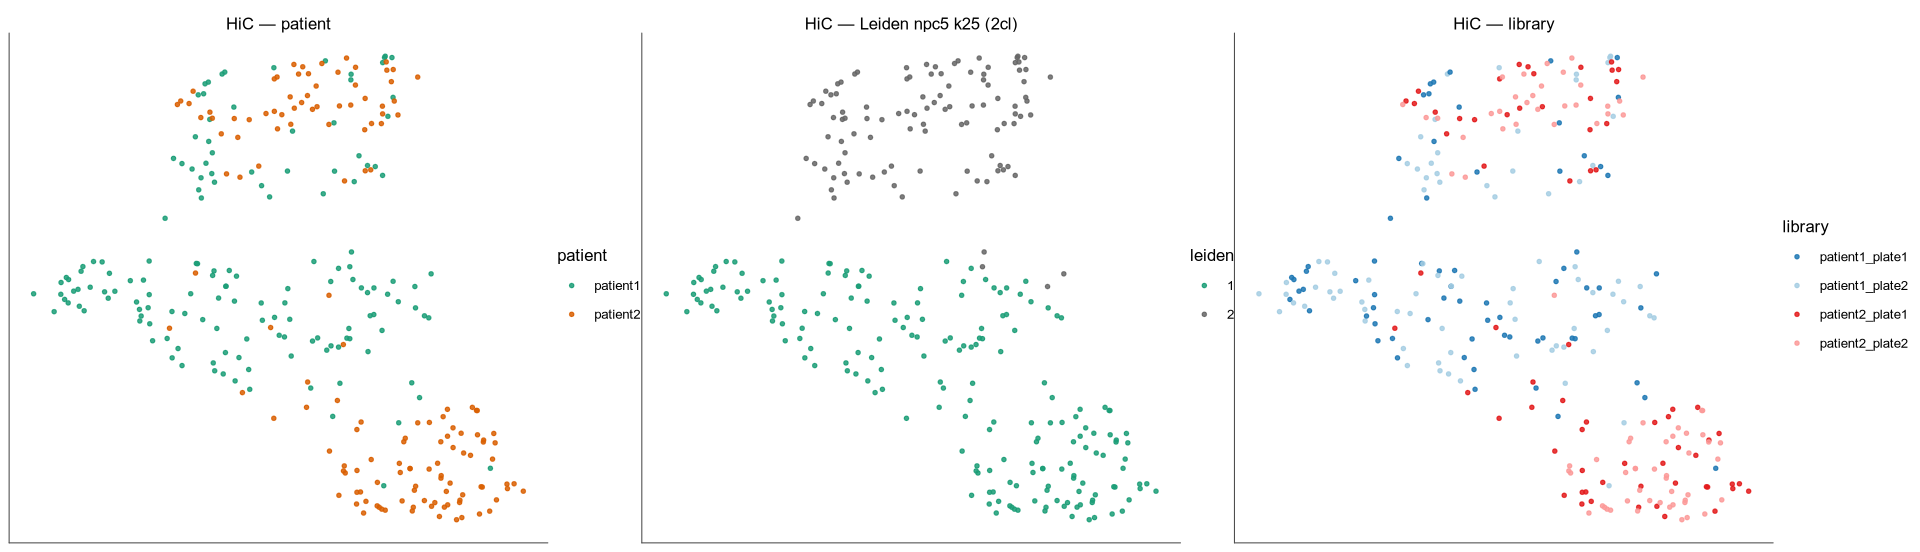

In [7]:
# §5b HiC final: UMAP + Leiden at n_pc=5, k=25, res=0.2 -> hic_cluster
set.seed(42)
HIC.umap <- freeze("HIC_umap", umap(as.matrix(HIC.harm[, 1:min(HIC_NPC, ncol(HIC.harm)), drop = FALSE]),
                 n_neighbors = max(2, min(HIC_K, nrow(HIC.harm) - 1)))$layout)
hic_cluster <- setNames(run_leiden(HIC.harm, HIC_NPC, HIC_K, LEIDEN_RES), rownames(HIC.harm))
submetadata$hic_cluster <- NA_integer_
submetadata[names(hic_cluster), "hic_cluster"] <- as.integer(hic_cluster)
cat("HiC Leiden:", length(unique(hic_cluster)), "clusters\n"); print(table(hic_cluster))
dfi <- data.frame(UMAP1=HIC.umap[,1], UMAP2=HIC.umap[,2],
                  patient=submetadata[rownames(HIC.umap),"patient"],
                  leiden=factor(hic_cluster[rownames(HIC.umap)]),
                  library=submetadata[rownames(HIC.umap),"library"])
options(repr.plot.width=16, repr.plot.height=4.6)
pI <- (ggplot(dfi,aes(UMAP1,UMAP2,colour=patient))+geom_point(size=.9,alpha=.85)+scale_colour_manual(values=PATIENT_PAL)+ggtitle("HiC — patient")+.tf) |
      (ggplot(dfi,aes(UMAP1,UMAP2,colour=leiden))+geom_point(size=.9,alpha=.85)+scale_colour_manual(values=pal_leiden(nlevels(dfi$leiden)))+ggtitle(sprintf("HiC — Leiden npc%d k%d (%dcl)",HIC_NPC,HIC_K,nlevels(dfi$leiden)))+.tf) |
      (ggplot(dfi,aes(UMAP1,UMAP2,colour=library))+geom_point(size=.9,alpha=.85)+scale_colour_manual(values=LIBRARY_PAL)+ggtitle("HiC — library")+.tf)
ggsave(file.path(OUT_FIG,"final_hic.pdf"), pI, width=16, height=4.6); pI

## §6 GCH accessibility — load → quantile → impute → SVD → Harmony(group) → UMAP + Leiden

In [8]:
# §6 GCH accessibility -> quantile-normalize -> impute -> SVD -> Harmony(top-20)
gch <- data.matrix(read.table(gzfile(file.path(WORKDIR, "QC", "methylation_matrices",
        "methylation_matrix_GCH_250kb.tsv.gz")), header = TRUE, sep = "\t",
        row.names = 1, check.names = FALSE, na.strings = c("NA", "", "NaN")))
gch <- gch[intersect(rownames(gch), submetadata$cell), , drop = FALSE]
gch <- gch[, colSums(is.na(gch)) < 0.5 * nrow(gch), drop = FALSE]
gch <- t(quantile_normalize(t(gch)))           # per-cell quantile normalize
gch <- perform_imputation(gch, 10)
GCH.svd <- svd_u(gch, 20)
meta_g <- submetadata[rownames(GCH.svd), ]
set.seed(42)
GCH.harm <- freeze("GCH_harm", RunHarmony(GCH.svd[, 1:min(20, ncol(GCH.svd))], meta_g, vars_use = "library", verbose = FALSE))
rownames(GCH.harm) <- rownames(GCH.svd)
cat("GCH: cells x SVD =", dim(GCH.svd), "| harmony dims =", dim(GCH.harm), "\n")

  [frozen] GCH_harm


GCH: cells x SVD = 292 292 | harmony dims = 292 20 


  [frozen] GCH_umap


GCH Leiden: 2 clusters


gch_cluster
  1   2 
225  67 


Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GCH — patient' in 'mbcsToSbcs': dot substituted for <e2>”


Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GCH — patient' in 'mbcsToSbcs': dot substituted for <80>”


Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GCH — patient' in 'mbcsToSbcs': dot substituted for <94>”


... (38 outputs left out)

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GCH — Leiden npc9 k25 (2cl)' in 'mbcsToSbcs': dot substituted for <94>”


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GCH — library' in 'mbcsToSbcs': dot substituted for <e2>”


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GCH — library' in 'mbcsToSbcs': dot substituted for <80>”


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GCH — library' in 'mbcsToSbcs': dot substituted for <94>”


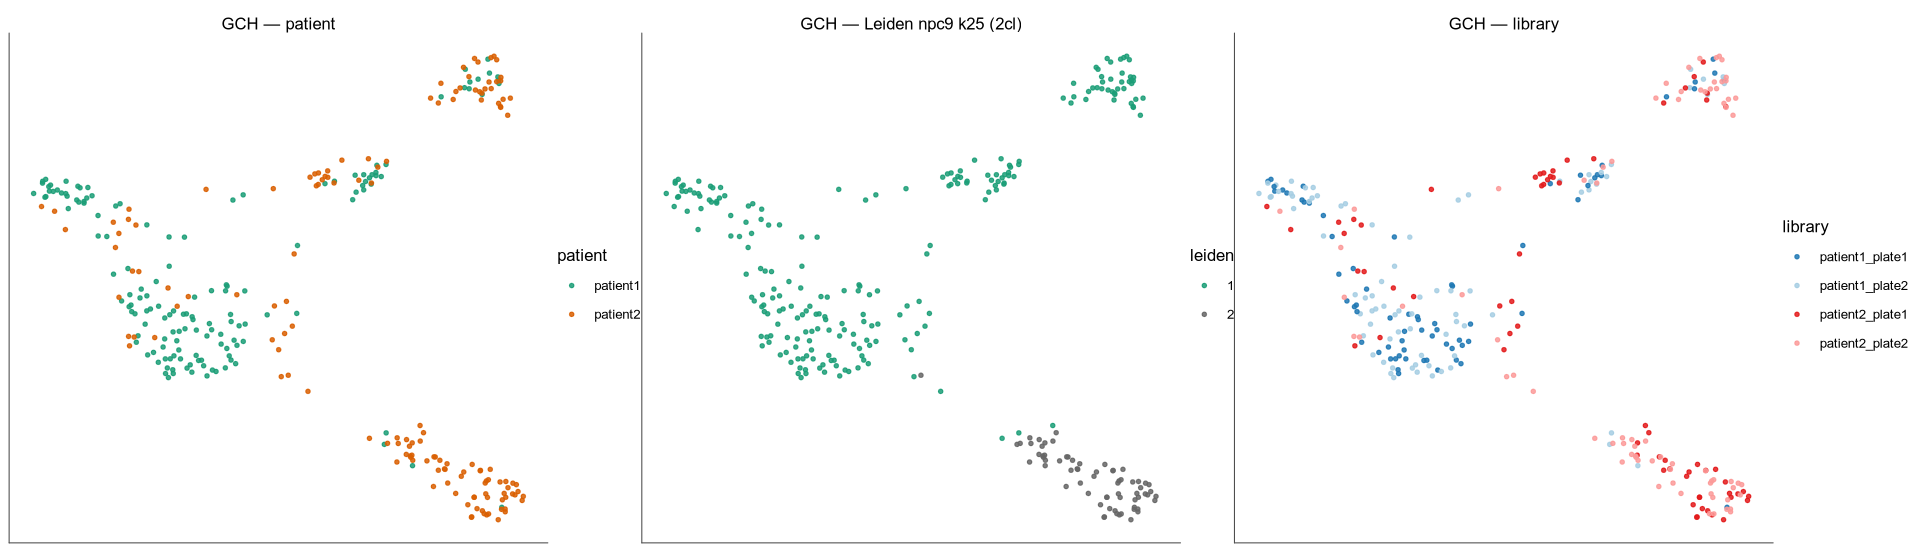

In [9]:
# §6b GCH final: UMAP + Leiden at n_pc=9, k=25, res=0.2 -> gch_cluster
set.seed(42)
GCH.umap <- freeze("GCH_umap", umap(as.matrix(GCH.harm[, 1:min(GCH_NPC, ncol(GCH.harm)), drop = FALSE]),
                 n_neighbors = max(2, min(GCH_K, nrow(GCH.harm) - 1)))$layout)
gch_cluster <- setNames(run_leiden(GCH.harm, GCH_NPC, GCH_K, LEIDEN_RES), rownames(GCH.harm))
submetadata$gch_cluster <- NA_integer_
submetadata[names(gch_cluster), "gch_cluster"] <- as.integer(gch_cluster)
cat("GCH Leiden:", length(unique(gch_cluster)), "clusters\n"); print(table(gch_cluster))
dfg <- data.frame(UMAP1=GCH.umap[,1], UMAP2=GCH.umap[,2],
                  patient=submetadata[rownames(GCH.umap),"patient"],
                  leiden=factor(gch_cluster[rownames(GCH.umap)]),
                  library=submetadata[rownames(GCH.umap),"library"])
options(repr.plot.width=16, repr.plot.height=4.6)
pG <- (ggplot(dfg,aes(UMAP1,UMAP2,colour=patient))+geom_point(size=.9,alpha=.85)+scale_colour_manual(values=PATIENT_PAL)+ggtitle("GCH — patient")+.tf) |
      (ggplot(dfg,aes(UMAP1,UMAP2,colour=leiden))+geom_point(size=.9,alpha=.85)+scale_colour_manual(values=pal_leiden(nlevels(dfg$leiden)))+ggtitle(sprintf("GCH — Leiden npc%d k%d (%dcl)",GCH_NPC,GCH_K,nlevels(dfg$leiden)))+.tf) |
      (ggplot(dfg,aes(UMAP1,UMAP2,colour=library))+geom_point(size=.9,alpha=.85)+scale_colour_manual(values=LIBRARY_PAL)+ggtitle("GCH — library")+.tf)
ggsave(file.path(OUT_FIG,"final_gch.pdf"), pG, width=16, height=4.6); pG

## §7 CNA group + per-modality 5-panel UMAPs

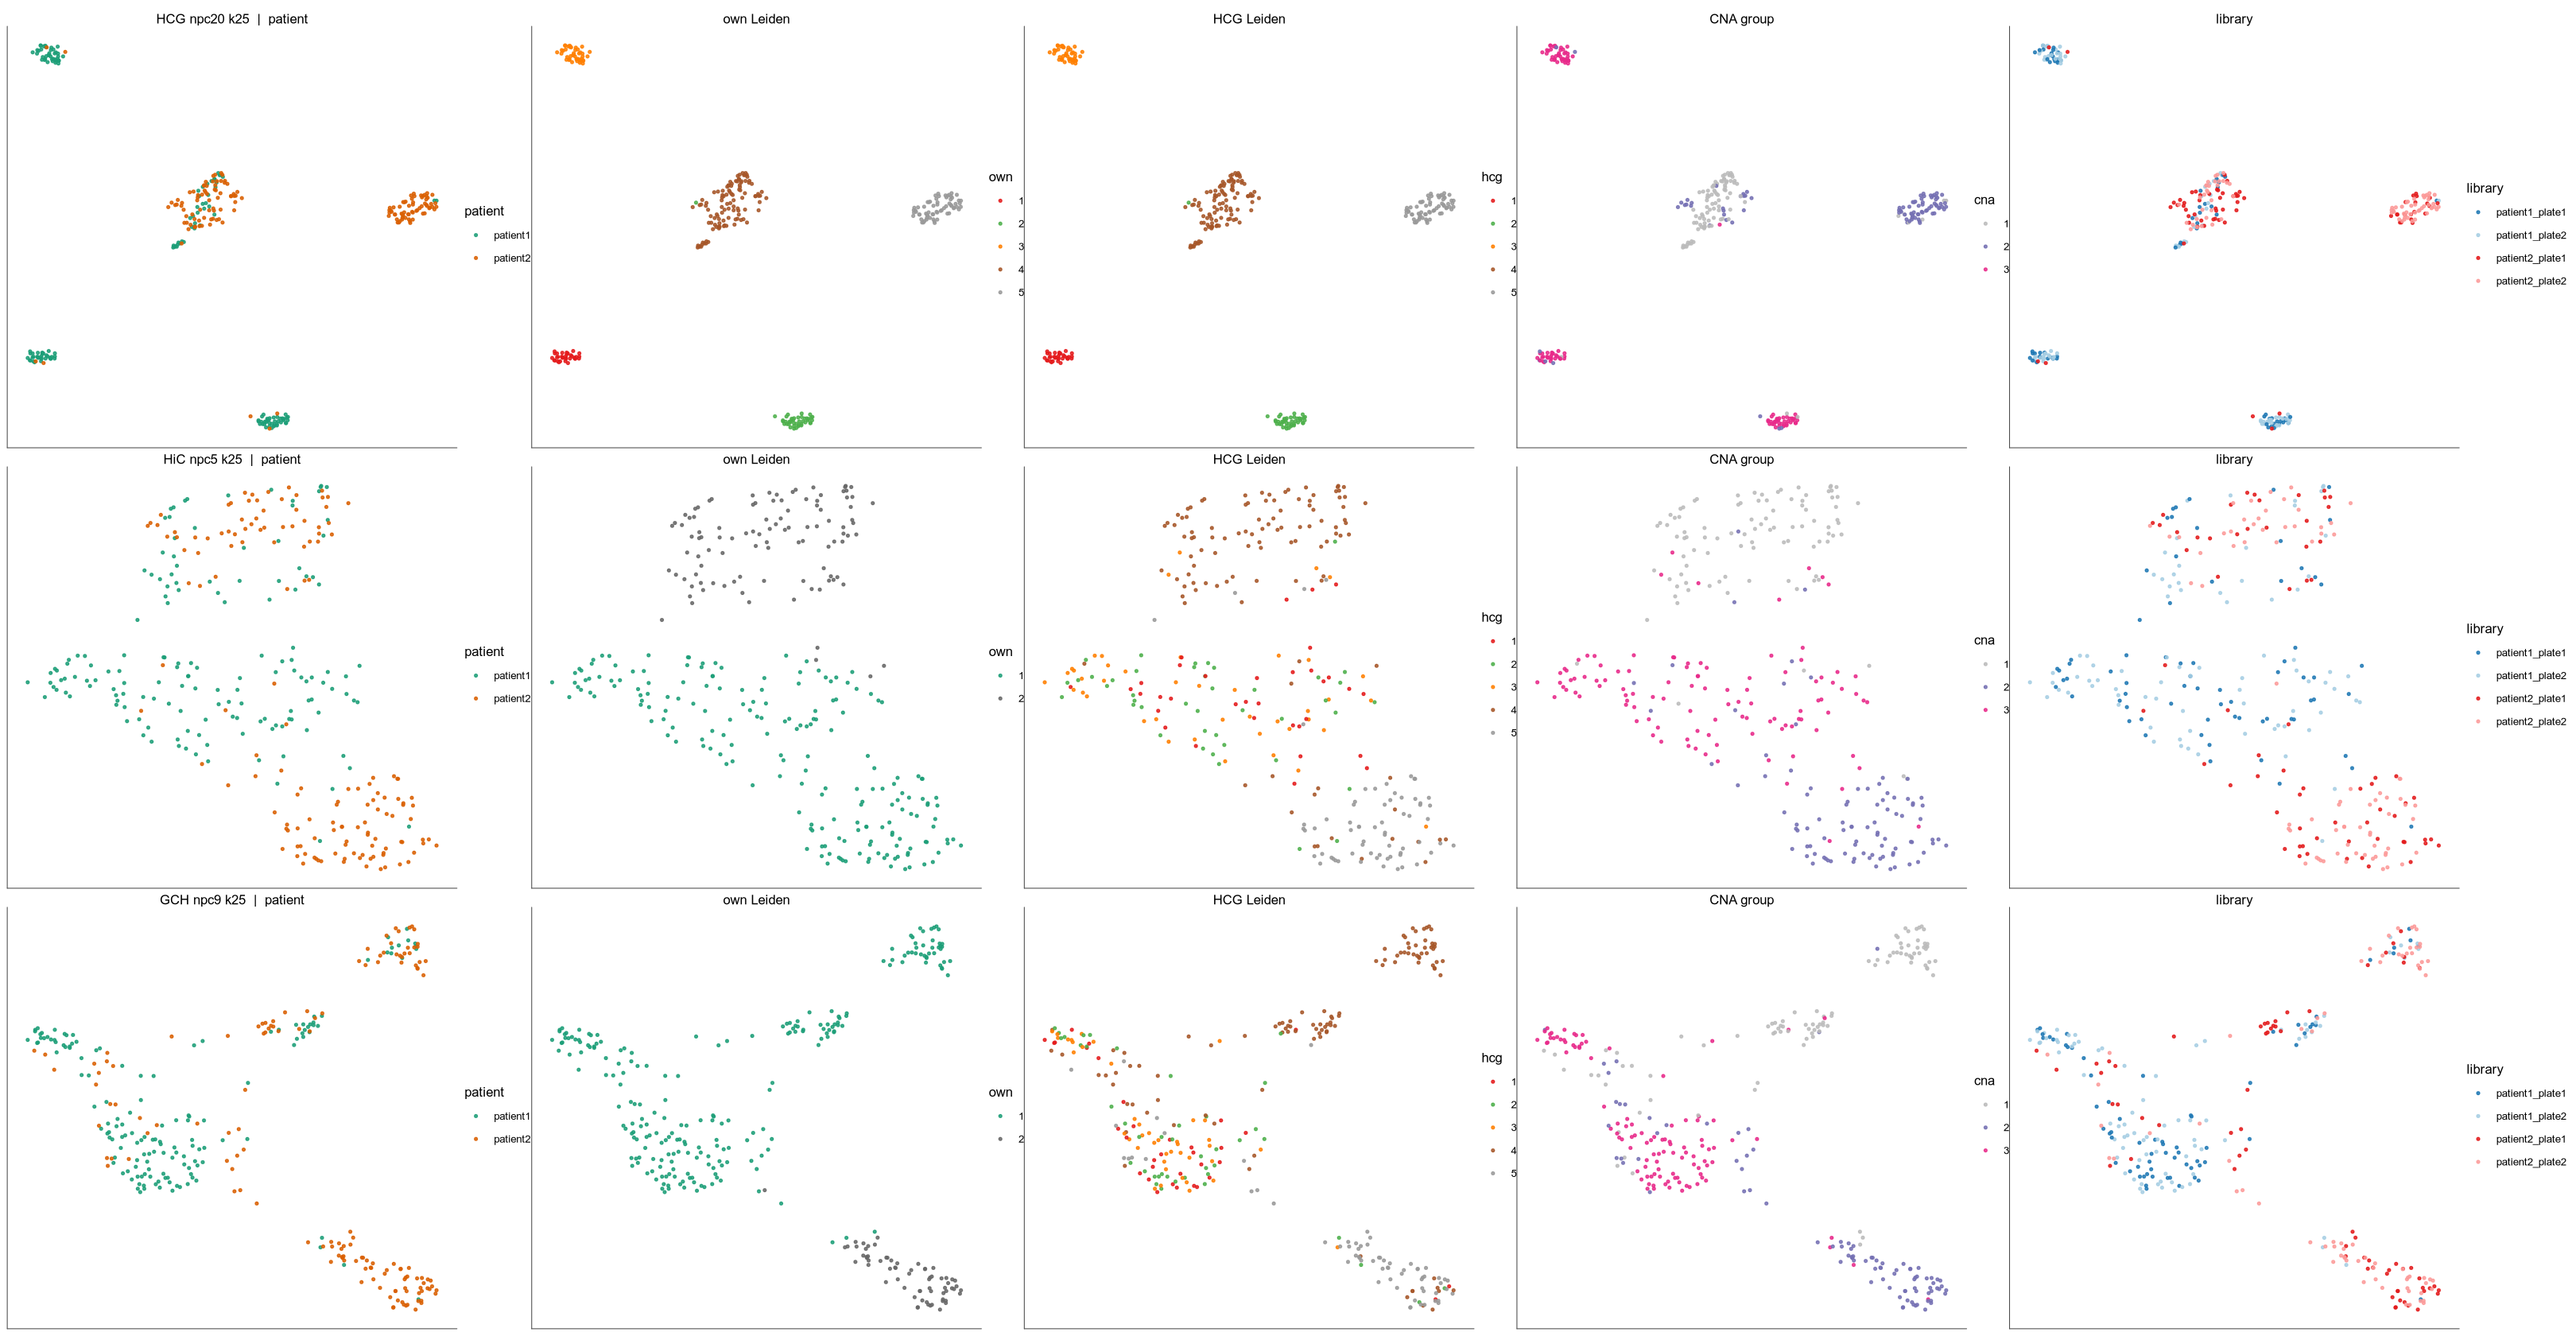

In [10]:
# §7 CNA group + per-modality 5-panel UMAPs (sample | own-Leiden | HCG-Leiden | CNA group | group)
# CNA group per cell: prefer chr1p+chr22q Approach-3 (3 groups), else Approach-1, else genome-wide.
.cna_f <- file.path(OUT_TAB, "cna_approach3_clusters.txt")
if (!file.exists(.cna_f)) .cna_f <- file.path(OUT_TAB, "cna_approach1_clusters.txt")
if (!file.exists(.cna_f)) .cna_f <- file.path(OUT_TAB, "cna_metadata_clusters.txt")
.cna_d <- read.table(.cna_f, header=TRUE, sep="\t", row.names=1, check.names=FALSE, stringsAsFactors=FALSE)
cna_group <- setNames(factor(as.character(.cna_d$cluster_cna),
                             levels=sort(unique(as.character(.cna_d$cluster_cna)))), rownames(.cna_d))
submetadata$cna_group <- NA_character_
.common <- intersect(rownames(submetadata), names(cna_group))
submetadata[.common, "cna_group"] <- as.character(cna_group[.common])

panel5 <- function(layout, own, own_name, own_pal) {
  df <- data.frame(UMAP1=layout[,1], UMAP2=layout[,2],
                   patient=submetadata[rownames(layout),"patient"],
                   own=factor(own[rownames(layout)]),
                   hcg=factor(hcg_cluster[rownames(layout)]),
                   cna=factor(as.character(cna_group[rownames(layout)]), levels=levels(cna_group)),
                   library=submetadata[rownames(layout),"library"])
  (ggplot(df,aes(UMAP1,UMAP2,colour=patient))+geom_point(size=.8,alpha=.85)+scale_colour_manual(values=PATIENT_PAL)+ggtitle(paste0(own_name,"  |  patient"))+.tf) |
  (ggplot(df,aes(UMAP1,UMAP2,colour=own))+geom_point(size=.8,alpha=.85)+scale_colour_manual(values=own_pal(nlevels(df$own)))+ggtitle("own Leiden")+.tf) |
  (ggplot(df,aes(UMAP1,UMAP2,colour=hcg))+geom_point(size=.8,alpha=.85)+scale_colour_manual(values=pal_hcg(nlevels(df$hcg)),na.value="grey85")+ggtitle("HCG Leiden")+.tf) |
  (ggplot(df,aes(UMAP1,UMAP2,colour=cna))+geom_point(size=.8,alpha=.85)+scale_colour_manual(values=CLONE_PAL,na.value="grey85",drop=TRUE)+ggtitle("CNA group")+.tf) |
  (ggplot(df,aes(UMAP1,UMAP2,colour=library))+geom_point(size=.8,alpha=.85)+scale_colour_manual(values=LIBRARY_PAL)+ggtitle("library")+.tf)
}
options(repr.plot.width=27, repr.plot.height=14)
pC <- panel5(HCG.umap, hcg_cluster, sprintf("HCG npc%d k%d", HCG_NPC, HCG_K), pal_hcg) /
      panel5(HIC.umap, hic_cluster, sprintf("HiC npc%d k%d", HIC_NPC, HIC_K), pal_leiden) /
      panel5(GCH.umap, gch_cluster, sprintf("GCH npc%d k%d", GCH_NPC, GCH_K), pal_leiden)
ggsave(file.path(OUT_FIG,"final_panels_all.pdf"), pC, width=27, height=14, limitsize=FALSE); pC

## §8 Joint embedding across HCG + Hi-C + GCH — UMAP + Leiden (for tumor/macrophage annotation)

cells in all 3 modalities: 292 


  [frozen] JOINT_umap


Joint Leiden: 3 clusters


joint_cluster
  1   2   3 
122  91  79 


joint cluster x CNA group (col 1 = CNA-normal):


             CNA
joint_cluster   1   2   3
            1   3  14 105
            2  87   3   1
            3   6  73   0


... (71 outputs left out)

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'joint — CNA group' in 'mbcsToSbcs': dot substituted for <94>”


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'joint — library' in 'mbcsToSbcs': dot substituted for <e2>”


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'joint — library' in 'mbcsToSbcs': dot substituted for <80>”


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'joint — library' in 'mbcsToSbcs': dot substituted for <94>”


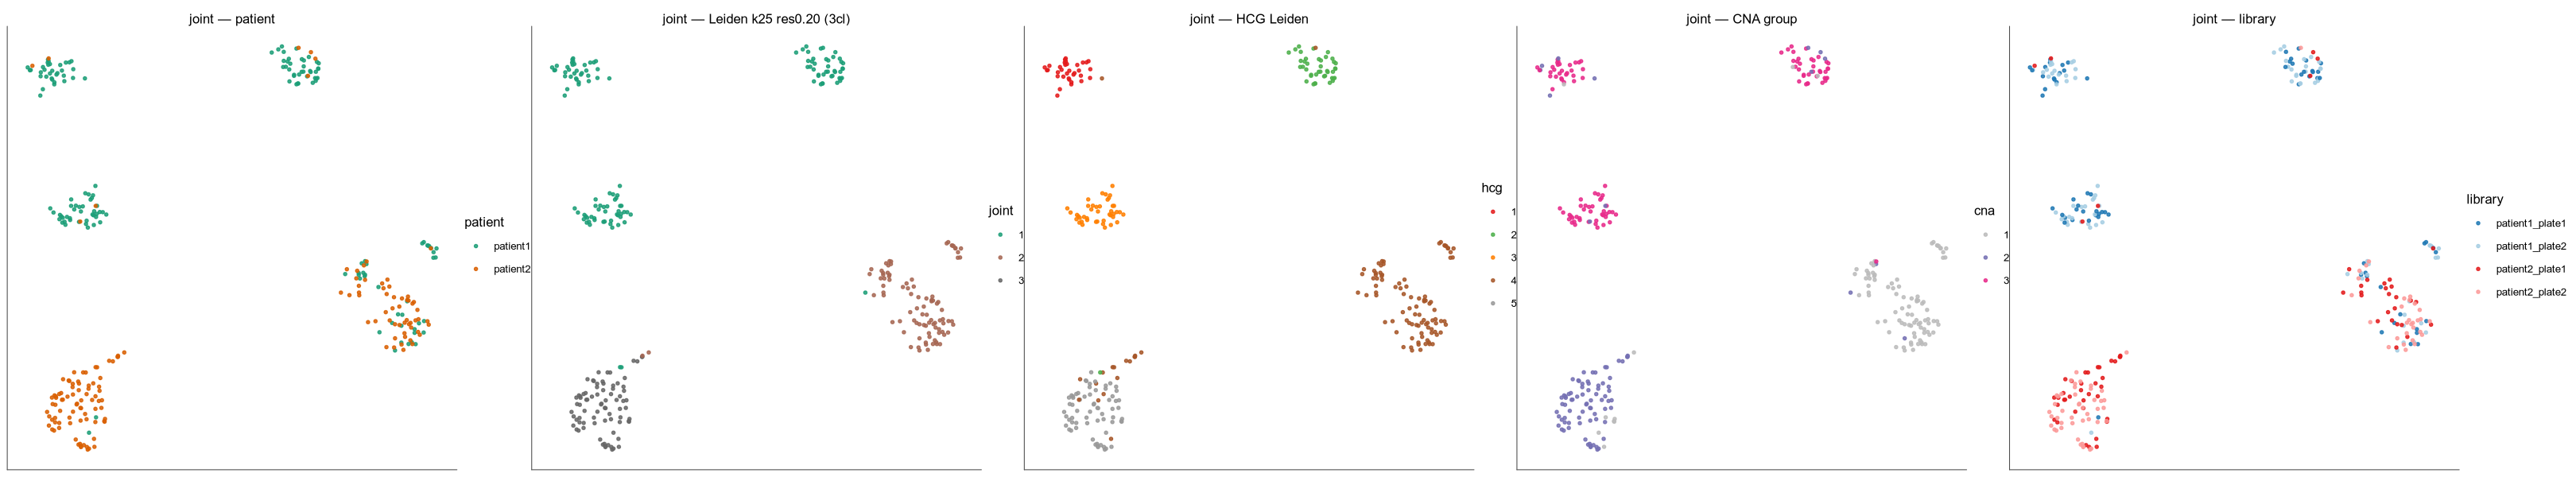

In [11]:
# §8 Joint embedding: z-score + concatenate the three Harmony embeddings -> UMAP
hcg_e <- HCG.harm[, 1:min(HCG_NPC, ncol(HCG.harm)), drop=FALSE]
hic_e <- HIC.harm[, 1:min(HIC_NPC, ncol(HIC.harm)), drop=FALSE]
gch_e <- GCH.harm[, 1:min(GCH_NPC, ncol(GCH.harm)), drop=FALSE]
shared <- Reduce(intersect, list(rownames(hcg_e), rownames(hic_e), rownames(gch_e)))
cat("cells in all 3 modalities:", length(shared), "\n")
joint <- cbind(scale(hcg_e[shared,,drop=FALSE]), scale(hic_e[shared,,drop=FALSE]), scale(gch_e[shared,,drop=FALSE]))
joint <- joint[, colSums(!is.finite(joint))==0, drop=FALSE]
set.seed(42)
JOINT.umap <- freeze("JOINT_umap", umap(as.matrix(joint))$layout); rownames(JOINT.umap) <- shared
# Leiden clustering ON the joint embedding -> joint_cluster (to be annotated tumor/macrophage/...)
joint_cluster <- setNames(run_leiden(joint, ncol(joint), JOINT_K, JOINT_RES), shared)
submetadata$joint_cluster <- NA_integer_
submetadata[names(joint_cluster), "joint_cluster"] <- as.integer(joint_cluster)
cat("Joint Leiden:", length(unique(joint_cluster)), "clusters\n"); print(table(joint_cluster))
# composition to help annotate tumor vs macrophage/normal: joint cluster x CNA group
# (CNA group 1 = normal/diploid -> immune e.g. macrophage; 2+/tumor = CNA-altered)
jc_cna <- table(joint_cluster = joint_cluster[shared],
                CNA = factor(as.character(cna_group[shared]), levels = levels(cna_group)))
cat("joint cluster x CNA group (col 1 = CNA-normal):\n"); print(jc_cna)
write.table(as.data.frame.matrix(jc_cna), file.path(OUT_TAB, "joint_cluster_vs_cna.tsv"),
            sep = "\t", quote = FALSE, col.names = NA)
dfj <- data.frame(UMAP1=JOINT.umap[,1], UMAP2=JOINT.umap[,2],
                  patient=submetadata[shared,"patient"],
                  joint=factor(joint_cluster[shared]),
                  hcg=factor(hcg_cluster[shared]),
                  cna=factor(as.character(cna_group[shared]), levels=levels(cna_group)),
                  library=submetadata[shared,"library"])
options(repr.plot.width=27, repr.plot.height=5)
pJ <- (ggplot(dfj,aes(UMAP1,UMAP2,colour=patient))+geom_point(size=.9,alpha=.85)+scale_colour_manual(values=PATIENT_PAL)+ggtitle("joint — patient")+.tf) |
      (ggplot(dfj,aes(UMAP1,UMAP2,colour=joint))+geom_point(size=.9,alpha=.85)+scale_colour_manual(values=pal_leiden(nlevels(dfj$joint)))+ggtitle(sprintf("joint — Leiden k%d res%.2f (%dcl)",JOINT_K,JOINT_RES,nlevels(dfj$joint)))+.tf) |
      (ggplot(dfj,aes(UMAP1,UMAP2,colour=hcg))+geom_point(size=.9,alpha=.85)+scale_colour_manual(values=pal_hcg(nlevels(dfj$hcg)))+ggtitle("joint — HCG Leiden")+.tf) |
      (ggplot(dfj,aes(UMAP1,UMAP2,colour=cna))+geom_point(size=.9,alpha=.85)+scale_colour_manual(values=CLONE_PAL,na.value="grey85",drop=TRUE)+ggtitle("joint — CNA group")+.tf) |
      (ggplot(dfj,aes(UMAP1,UMAP2,colour=library))+geom_point(size=.9,alpha=.85)+scale_colour_manual(values=LIBRARY_PAL)+ggtitle("joint — library")+.tf)
ggsave(file.path(OUT_FIG,"final_joint_umap.pdf"), pJ, width=27, height=5); pJ

## §8b Cell-type annotation — two versions: JOINT-based (1=tumor1,2=macrophage,3=tumor2) and HCG-based (1/2/3=tumor1,4=macrophage,5=tumor2)

cell_type_joint:



macrophage   tumor1   tumor2 
      91      122       79 


cell_type_hcg:



macrophage   tumor1   tumor2 
     108      118       66 


Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'joint UMAP — cell_type (JOINT-based)' in 'mbcsToSbcs': dot substituted for <e2>”


Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'joint UMAP — cell_type (JOINT-based)' in 'mbcsToSbcs': dot substituted for <80>”


... (24 outputs left out)

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'joint UMAP — cell_type (JOINT-based)' in 'mbcsToSbcs': dot substituted for <94>”


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'joint UMAP — cell_type (HCG-based)' in 'mbcsToSbcs': dot substituted for <e2>”


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'joint UMAP — cell_type (HCG-based)' in 'mbcsToSbcs': dot substituted for <80>”


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'joint UMAP — cell_type (HCG-based)' in 'mbcsToSbcs': dot substituted for <94>”


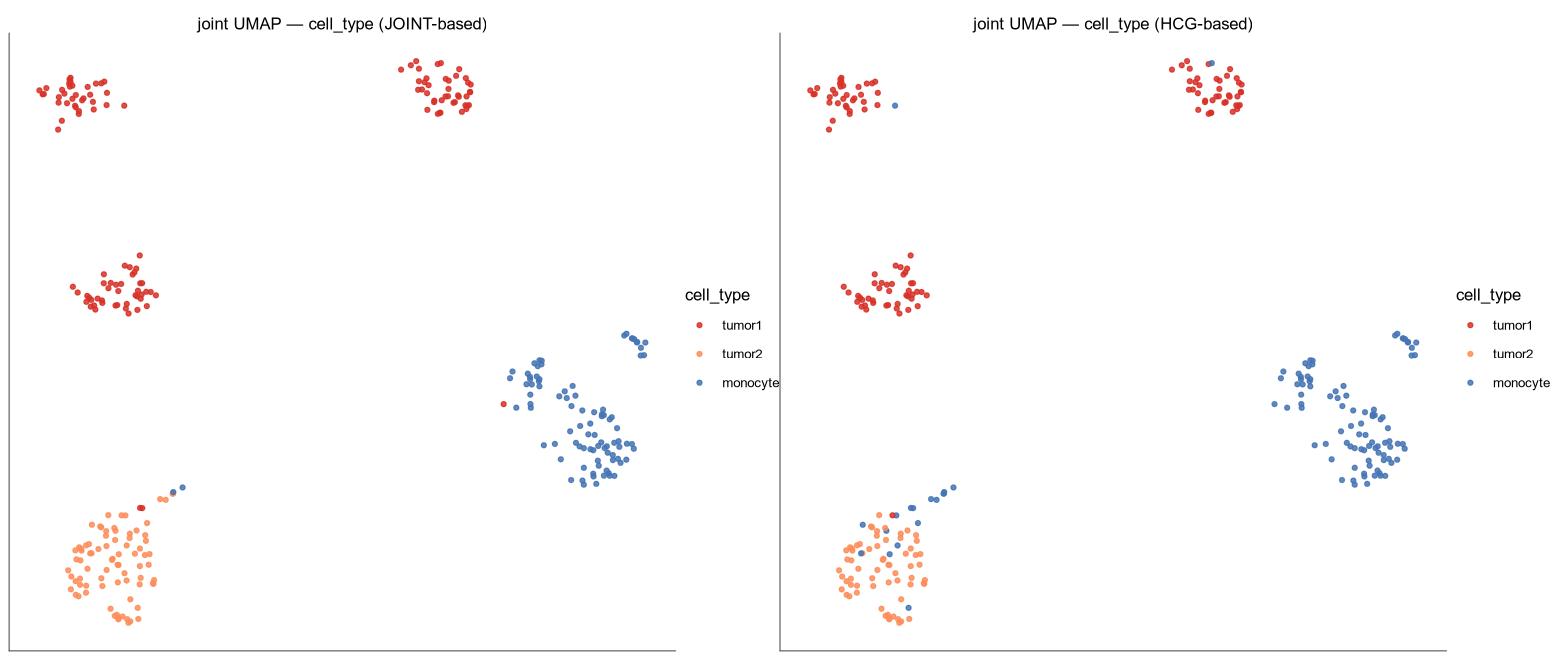

In [12]:
# §8b Cell-type annotation — TWO versions so you can CHOOSE which to use:
#   (a) cell_type_joint from the JOINT clusters   (b) cell_type_hcg from the HCG clusters.
# EDIT the maps as needed. Unmapped clusters -> "other".
JOINT_ANNOT <- c("1" = "tumor1", "2" = "macrophage", "3" = "tumor2")               # joint_cluster
HCG_ANNOT   <- c("1" = "tumor1", "2" = "tumor1", "3" = "tumor1",                 # hcg_cluster
                 "4" = "macrophage", "5" = "tumor2")
CELLTYPE_PAL <- c(tumor1 = "#D73027", tumor2 = "#FC8D59", macrophage = "#4575B4", other = "grey70")
annot_from <- function(cluster_col, map) {
  ct <- unname(map[as.character(submetadata[[cluster_col]])])
  ct[!is.na(submetadata[[cluster_col]]) & is.na(ct)] <- "other"; ct
}
submetadata$cell_type_joint <- annot_from("joint_cluster", JOINT_ANNOT)
submetadata$cell_type_hcg   <- annot_from("hcg_cluster",   HCG_ANNOT)
cat("cell_type_joint:\n"); print(table(submetadata$cell_type_joint, useNA = "ifany"))
cat("cell_type_hcg:\n");   print(table(submetadata$cell_type_hcg,   useNA = "ifany"))
# labeled joint UMAP for each annotation, side by side
mk_ct <- function(col, ttl) {
  cc <- shared[!is.na(submetadata[shared, col])]
  df <- data.frame(UMAP1 = JOINT.umap[cc,1], UMAP2 = JOINT.umap[cc,2],
                   cell_type = factor(submetadata[cc, col], levels = names(CELLTYPE_PAL)))
  ggplot(df, aes(UMAP1, UMAP2, colour = cell_type)) + geom_point(size = 1.1, alpha = .85) +
    scale_colour_manual(values = CELLTYPE_PAL, drop = TRUE) + ggtitle(ttl) + .tf
}
options(repr.plot.width = 13, repr.plot.height = 5.5)
pA <- mk_ct("cell_type_joint", "joint UMAP — cell_type (JOINT-based)") |
      mk_ct("cell_type_hcg",   "joint UMAP — cell_type (HCG-based)")
ggsave(file.path(OUT_FIG, "final_celltype_umap.pdf"), pA, width = 13, height = 5.5); pA

## §8c Four-panel per-modality + joint UMAPs (cortex Fig.4b style) — cell_type (joint), cell_type (HCG), and CNA group

wrote figures/final_umap_fig4b_joint.pdf


wrote figures/final_umap_fig4b_hcg.pdf


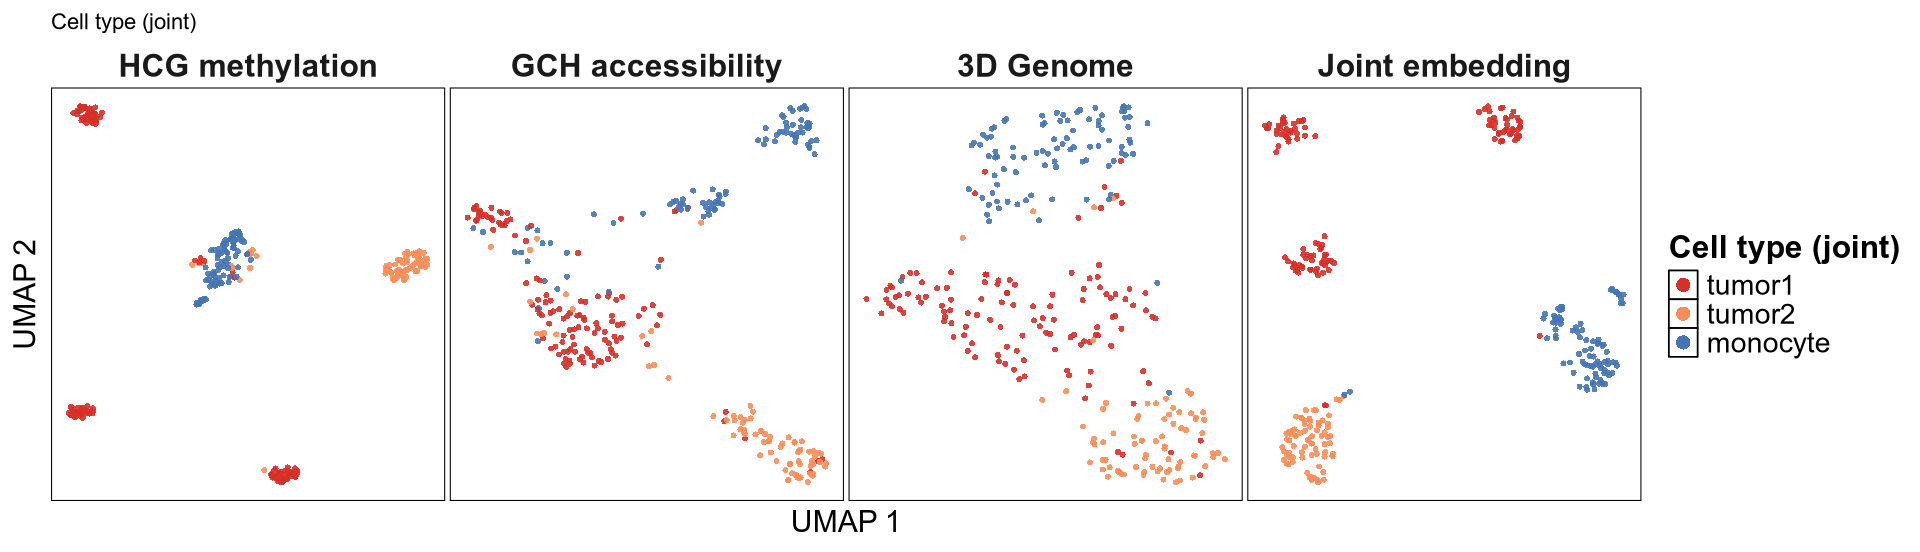

wrote figures/final_umap_fig4b_cna.pdf


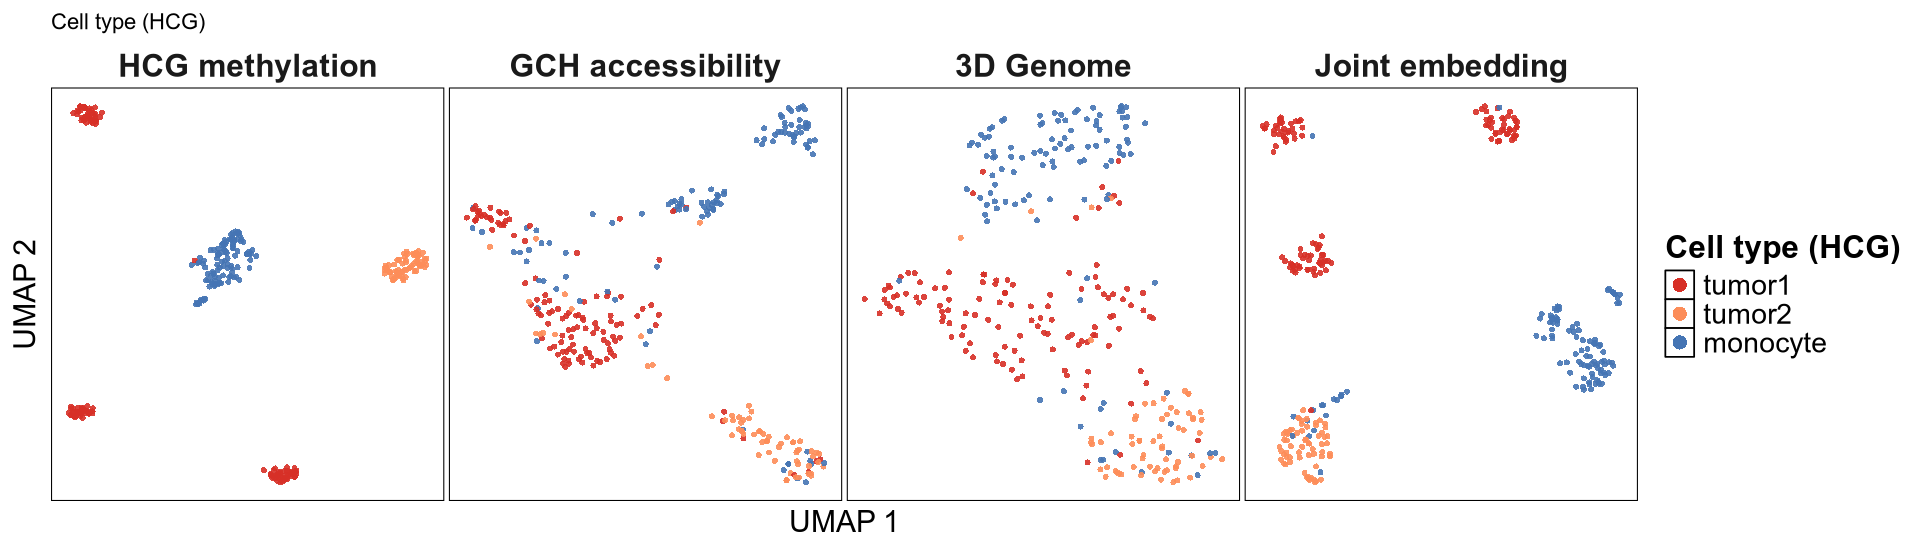

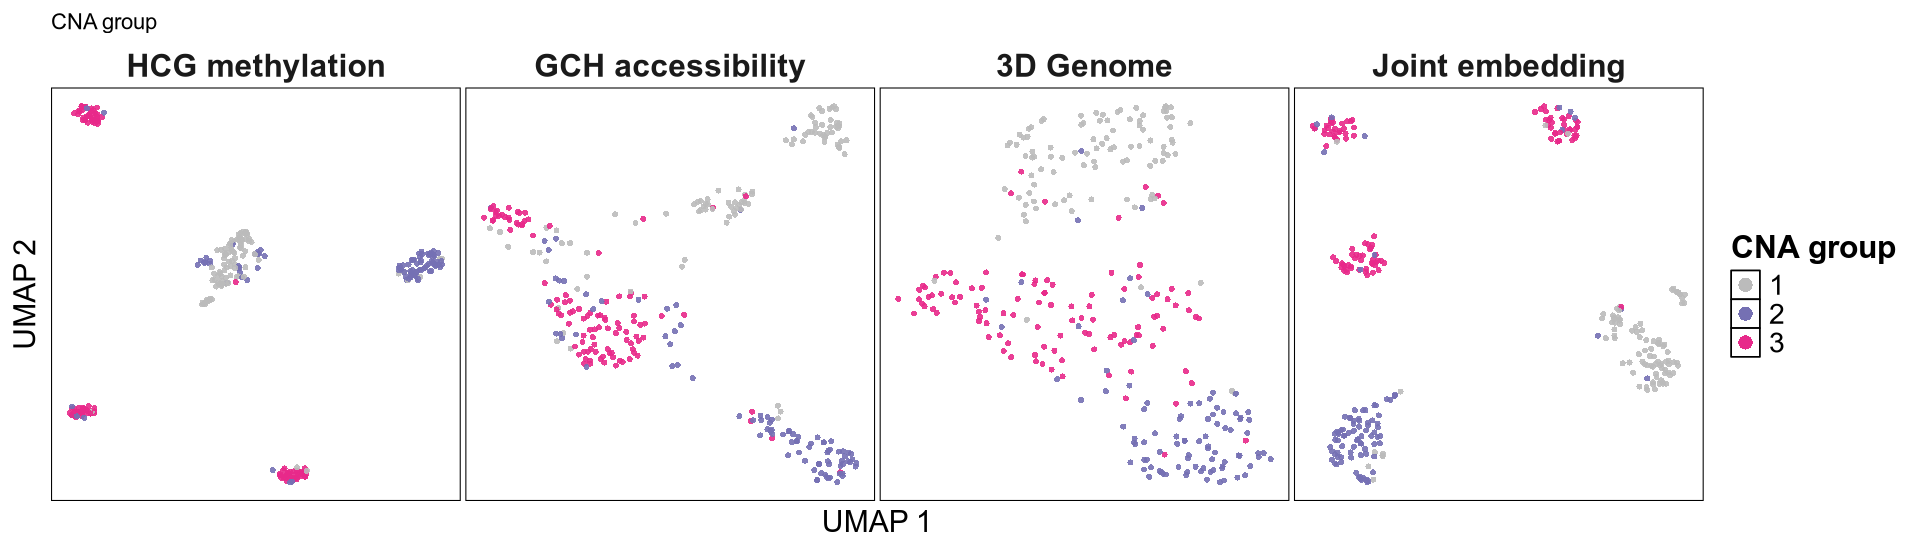

In [13]:
# §8c Four-panel per-modality + joint UMAPs (cortex Fig. 4b style): HCG / GCH / Hi-C / Joint.
# Produced for THREE colorings so you can compare: cell_type (joint-based), cell_type (HCG-based),
# and CNA group. `col`/`pal`/`legname` select the coloring; unused palette levels are dropped.
build_mod_df <- function(layout, modality, col, pal) {
  cells <- intersect(rownames(layout), rownames(submetadata))
  data.frame(cell = cells, UMAP1 = layout[cells, 1], UMAP2 = layout[cells, 2],
             grp = factor(submetadata[cells, col], levels = names(pal)),
             modality = modality, stringsAsFactors = FALSE)
}
fig4b <- function(col, tag, pal, legname) {
  panels <- list(build_mod_df(HCG.umap,   "HCG methylation",   col, pal),
                 build_mod_df(GCH.umap,   "GCH accessibility", col, pal),
                 build_mod_df(HIC.umap,   "3D Genome",         col, pal),
                 build_mod_df(JOINT.umap, "Joint embedding",   col, pal))
  plev <- vapply(panels, function(p) p$modality[1], character(1))
  d <- do.call(rbind, panels); d$modality <- factor(d$modality, levels = plev)
  d <- d[!is.na(d$grp), ]
  PUB_BASE <- 16
  th <- theme(panel.background = element_blank(), panel.grid = element_blank(),
    panel.border = element_rect(colour = "black", fill = NA, linewidth = 0.6),
    axis.text = element_blank(), axis.ticks = element_blank(),
    axis.title = element_text(size = PUB_BASE + 2), strip.background = element_blank(),
    strip.text = element_text(size = PUB_BASE + 3, face = "bold"),
    legend.title = element_text(size = PUB_BASE + 3, face = "bold"),
    legend.text = element_text(size = PUB_BASE + 1), legend.key = element_rect(fill = "white"),
    legend.position = "right", panel.spacing.x = unit(0, "lines"), plot.margin = margin(8, 8, 8, 8))
  p <- ggplot(d, aes(UMAP1, UMAP2, colour = grp)) +
    geom_point(size = 1.7, alpha = 0.9, stroke = 0) +
    scale_color_manual(values = pal, name = legname, na.value = "grey80", drop = TRUE) +
    facet_wrap(~ modality, nrow = 1, scales = "free") + labs(x = "UMAP 1", y = "UMAP 2") + th +
    guides(colour = guide_legend(override.aes = list(size = 4, alpha = 1)))
  ggsave(file.path(OUT_FIG, sprintf("final_umap_fig4b_%s.pdf", tag)), p, width = 16, height = 4.6)
  cat("wrote figures/final_umap_fig4b_", tag, ".pdf\n", sep = "")
  p + ggtitle(legname)
}
options(repr.plot.width = 16, repr.plot.height = 4.6)   # each figure shown separately
print(fig4b("cell_type_joint", "joint", CELLTYPE_PAL, "Cell type (joint)"))
print(fig4b("cell_type_hcg",   "hcg",   CELLTYPE_PAL, "Cell type (HCG)"))
print(fig4b("cna_group",       "cna",   CLONE_PAL,    "CNA group"))

## §8d Concordance of each embedding with CNA group (kNN purity + bootstrap 95% CI; ARI/NMI)

concordance on 292 cells, 3 CNA groups; K = 30 


ARI/NMI clustering: k-means with K = 3 (matched to #CNA groups)


 embedding     metric value    lo    hi
       HCG kNN purity 0.854 0.820 0.887
       HCG        ARI 0.657 0.570 0.747
       HCG        NMI 0.616 0.544 0.705
       HiC kNN purity 0.822 0.793 0.850
       HiC        ARI 0.510 0.425 0.603
       HiC        NMI 0.514 0.451 0.601
       GCH kNN purity 0.780 0.743 0.814
       GCH        ARI 0.540 0.446 0.645
       GCH        NMI 0.525 0.446 0.621
     Joint kNN purity 0.874 0.842 0.904
     Joint        ARI 0.731 0.649 0.815
     Joint        NMI 0.698 0.630 0.786


chance-level kNN purity (random labels) = 0.335



Paired Joint - X (paired-bootstrap 95% CI; p: purity=Wilcoxon signed-rank, ARI/NMI=bootstrap; Holm within metric):


     metric  vs  delta      lo     hi  p_value   p_holm      test
 kNN purity HCG 0.0196 0.00559 0.0350 1.43e-03 1.43e-03  wilcoxon
 kNN purity HiC 0.0516 0.02237 0.0827 6.07e-06 1.21e-05  wilcoxon
 kNN purity GCH 0.0934 0.06541 0.1217 6.51e-15 1.95e-14  wilcoxon
        ARI HCG 0.0732 0.03080 0.1204 5.00e-04 1.50e-03 bootstrap
        ARI HiC 0.2212 0.11885 0.3280 5.00e-04 1.50e-03 bootstrap
        ARI GCH 0.1912 0.08665 0.2847 1.00e-03 1.50e-03 bootstrap
        NMI HCG 0.0821 0.04217 0.1266 5.00e-04 1.50e-03 bootstrap
        NMI HiC 0.1838 0.10409 0.2692 5.00e-04 1.50e-03 bootstrap
        NMI GCH 0.1730 0.08766 0.2538 5.00e-04 1.50e-03 bootstrap


... (2 outputs left out)

| --- | --- | --- | --- | --- | --- |


| kNN purity | GCH | +0.093 | 0.780 | +12.0% | 2e-14 |
| kNN purity | HiC | +0.052 | 0.822 | +6.3% | 1.2e-05 |
| kNN purity | HCG | +0.020 | 0.854 | +2.3% | 0.0014 |
| ARI | HiC | +0.221 | 0.510 | +43.4% | 0.0015 |
| ARI | GCH | +0.191 | 0.540 | +35.4% | 0.0015 |
| ARI | HCG | +0.073 | 0.657 | +11.1% | 0.0015 |
| NMI | HiC | +0.184 | 0.514 | +35.7% | 0.0015 |
| NMI | GCH | +0.173 | 0.525 | +32.9% | 0.0015 |
| NMI | HCG | +0.082 | 0.616 | +13.3% | 0.0015 |


  Biggest ABSOLUTE gap: Joint - HiC on ARI = +0.221 (**)


  Biggest RELATIVE gap: Joint - HiC on ARI = +43% of HiC


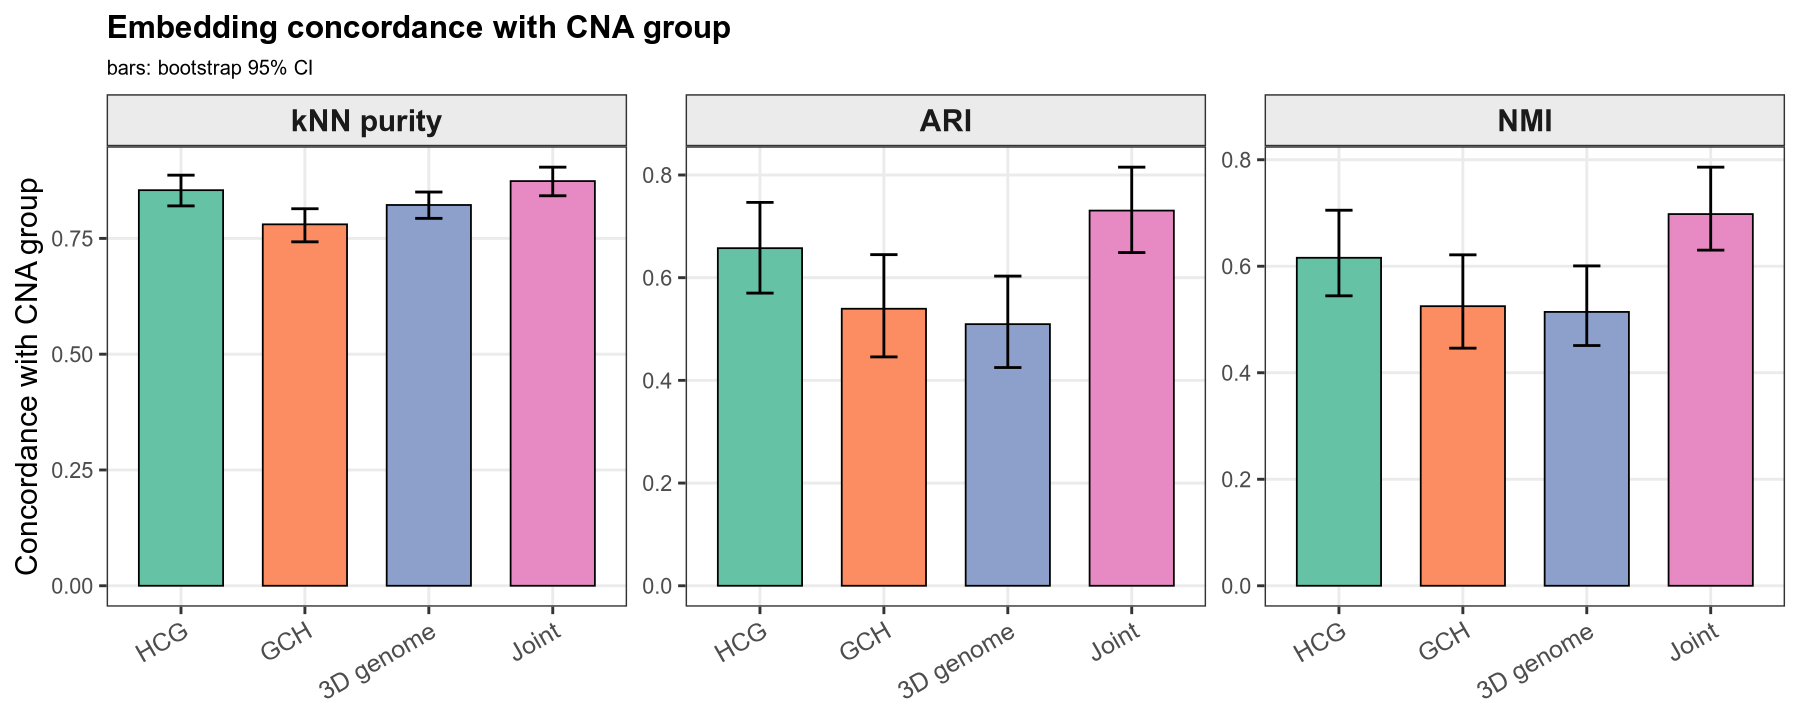

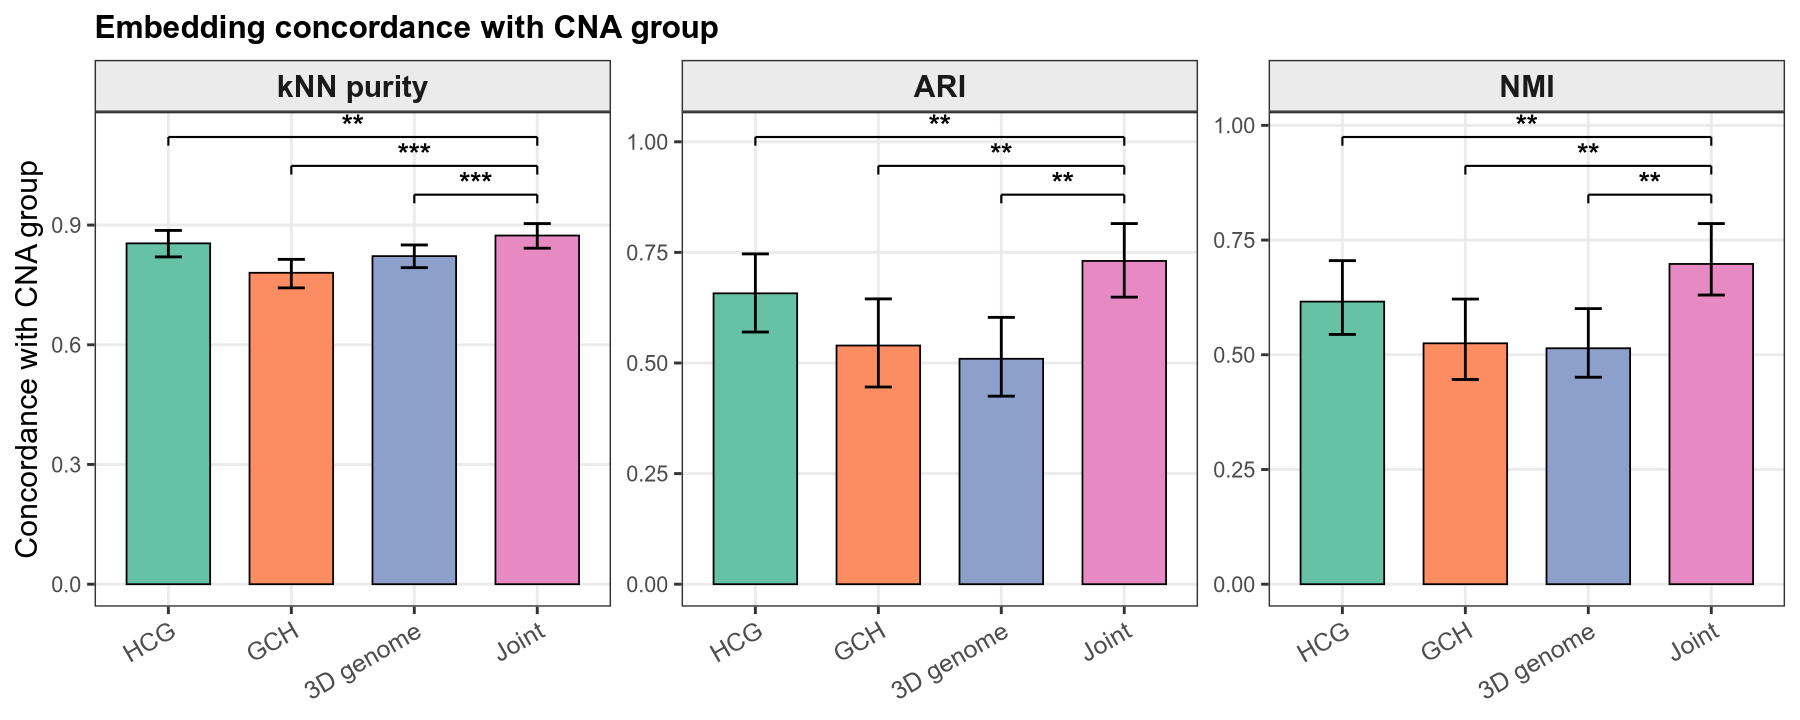

In [14]:
# §8d Quantitative concordance of each embedding with the CNA group labels.
# Primary metric: kNN LABEL PURITY — for each cell, the fraction of its K nearest neighbours
# (in the embedding) that share its CNA group; reported as the mean over cells with a
# bootstrap 95% CI (resampling cells). Chance baseline = sum(p_g^2). Secondary: ARI and NMI
# between a k-means clustering (K = #CNA groups) of each embedding and the CNA groups. Tests the claim that the
# JOINT embedding is most concordant with CNA.
K_CONC <- 30; B_BOOT <- 2000
common <- shared[!is.na(cna_group[shared])]                 # shared cells that carry a CNA group
lab <- droplevels(factor(cna_group[common]))
cat("concordance on", length(common), "cells,", nlevels(lab), "CNA groups; K =", K_CONC, "\n")

knn_purity_vec <- function(E, labels, k) {                  # per-cell kNN label purity
  E <- E[, apply(E, 2, function(x) sd(x) > 0), drop = FALSE]; E <- scale(E)
  D <- as.matrix(dist(E)); n <- nrow(E); k <- min(k, n - 1)
  vapply(seq_len(n), function(i) mean(labels[order(D[i, ])[2:(k + 1)]] == labels[i]), numeric(1))
}
boot_ci <- function(p, B) {                                 # bootstrap 95% CI of the mean
  m <- replicate(B, mean(sample(p, length(p), replace = TRUE)))
  c(purity = mean(p), lo = unname(quantile(m, .025)), hi = unname(quantile(m, .975)))
}
nmi <- function(a, b) {                                     # normalized mutual information
  a <- as.integer(factor(a)); b <- as.integer(factor(b)); n <- length(a); tab <- table(a, b)
  H <- function(x) { p <- x / sum(x); p <- p[p > 0]; -sum(p * log(p)) }
  Ha <- H(rowSums(tab)); Hb <- H(colSums(tab)); I <- 0
  for (i in seq_len(nrow(tab))) for (j in seq_len(ncol(tab)))
    if (tab[i, j] > 0) I <- I + (tab[i, j] / n) * log((tab[i, j] * n) / (sum(tab[i, ]) * sum(tab[, j])))
  if (Ha + Hb == 0) 0 else 2 * I / (Ha + Hb)
}
embs <- list(HCG = hcg_e[common, , drop = FALSE], HiC = hic_e[common, , drop = FALSE],
             GCH = gch_e[common, , drop = FALSE], Joint = joint[common, , drop = FALSE])
npc_map <- c(HCG = HCG_NPC, HiC = HIC_NPC, GCH = GCH_NPC, Joint = ncol(joint))
pv   <- lapply(embs, function(E) knn_purity_vec(E, lab, K_CONC))   # per-cell purity per embedding
# For ARI/NMI, cluster EVERY embedding into exactly K = (#CNA groups) so the cluster count is
# matched and the indices are comparable across embeddings (Leiden at a fixed resolution gives
# different cluster counts per embedding, which biases ARI/NMI). k-means on the scaled embedding.
KC <- nlevels(lab)
cls  <- setNames(lapply(embs, function(E) {
  Es <- scale(E[, apply(E, 2, function(x) sd(x) > 0), drop = FALSE]); set.seed(42)
  kmeans(Es, centers = KC, nstart = 25)$cluster
}), names(embs))
labi <- as.integer(lab); n <- length(common); chance <- sum((table(lab) / n)^2)
cat("ARI/NMI clustering: k-means with K =", KC, "(matched to #CNA groups)\n")
# Bootstrap CI (over CELLS) of a metric fn(idx) computed on a cell subset. For kNN purity the
# neighbour graph is fixed (we resample the precomputed per-cell purities); for ARI/NMI we
# resample cells and recompute the index on the fixed (cluster, CNA) pairs -- no re-clustering.
metric_ci <- function(fn) {
  bs <- replicate(B_BOOT, fn(sample(n, n, replace = TRUE)))
  c(value = fn(seq_len(n)), lo = unname(quantile(bs, .025)), hi = unname(quantile(bs, .975)))
}
conc_long <- do.call(rbind, lapply(names(embs), function(nm) {
  p <- pv[[nm]]; cl <- cls[[nm]]
  cp <- metric_ci(function(i) mean(p[i]))
  ca <- metric_ci(function(i) adj_rand(cl[i], labi[i]))
  cn <- metric_ci(function(i) nmi(cl[i], labi[i]))
  data.frame(embedding = nm, metric = c("kNN purity", "ARI", "NMI"),
             value = c(cp["value"], ca["value"], cn["value"]),
             lo    = c(cp["lo"],    ca["lo"],    cn["lo"]),
             hi    = c(cp["hi"],    ca["hi"],    cn["hi"]), row.names = NULL)
}))
conc_long$embedding <- factor(conc_long$embedding, levels = c("HCG", "GCH", "HiC", "Joint"))
conc_long$metric    <- factor(conc_long$metric,    levels = c("kNN purity", "ARI", "NMI"))
print(conc_long, row.names = FALSE, digits = 3)
cat(sprintf("chance-level kNN purity (random labels) = %.3f\n", chance))
# Paired significance test, Joint vs each other embedding, on ALL THREE metrics. The 95% CI of the
# Joint-X difference always comes from a PAIRED bootstrap (same resampled cells for Joint and X).
# The p-value uses the most appropriate test PER METRIC:
#   * kNN purity  -> one-sided Wilcoxon SIGNED-RANK on the per-cell differences (Joint-X per cell);
#                    powerful and can resolve very small p (not floored by the bootstrap 1/(B+1)).
#   * ARI / NMI   -> these are PARTITION-level scalars with no per-cell value, so a signed-rank test
#                    can't apply; p = fraction of paired-bootstrap resamples where Joint does NOT
#                    beat X (Joint-X <= 0), add-one smoothed (one-sided).
# Holm-corrected within each metric (3 comparisons: Joint vs HCG/HiC/GCH).
stars <- function(p) ifelse(p < .001, "***", ifelse(p < .01, "**", ifelse(p < .05, "*", "ns")))
mfun <- list("kNN purity" = function(nm, i) mean(pv[[nm]][i]),
             "ARI"        = function(nm, i) adj_rand(cls[[nm]][i], labi[i]),
             "NMI"        = function(nm, i) nmi(cls[[nm]][i], labi[i]))
set.seed(1)
BI <- replicate(B_BOOT, sample(n, n, replace = TRUE), simplify = FALSE)   # shared cell resamples
pvals <- do.call(rbind, lapply(names(mfun), function(mt) {
  f <- mfun[[mt]]
  do.call(rbind, lapply(c("HCG", "HiC", "GCH"), function(nm) {
    dobs <- f("Joint", seq_len(n)) - f(nm, seq_len(n))
    bd   <- vapply(BI, function(i) f("Joint", i) - f(nm, i), numeric(1))   # paired-bootstrap diffs -> CI
    p    <- if (mt == "kNN purity")
              suppressWarnings(wilcox.test(pv[["Joint"]], pv[[nm]], paired = TRUE, alternative = "greater")$p.value)
            else (1 + sum(bd <= 0)) / (B_BOOT + 1)
    data.frame(metric = mt, vs = nm, delta = dobs, lo = unname(quantile(bd, .025)),
               hi = unname(quantile(bd, .975)), p_value = p, row.names = NULL)
  }))
}))
pvals$p_holm <- ave(pvals$p_value, pvals$metric, FUN = function(p) p.adjust(p, "holm"))
pvals$test   <- ifelse(pvals$metric == "kNN purity", "wilcoxon", "bootstrap")
pvals$metric <- factor(pvals$metric, levels = c("kNN purity", "ARI", "NMI"))
cat("\nPaired Joint - X (paired-bootstrap 95% CI; p: purity=Wilcoxon signed-rank, ARI/NMI=bootstrap; Holm within metric):\n")
print(pvals, row.names = FALSE, digits = 3)
write.table(conc_long, file.path(OUT_TAB, "embedding_cna_concordance.tsv"), sep = "\t", quote = FALSE, row.names = FALSE)
write.table(pvals,     file.path(OUT_TAB, "embedding_cna_concordance_paired.tsv"), sep = "\t", quote = FALSE, row.names = FALSE)
# Joint-vs-X improvement TABLE for EVERY comparison (Joint vs HCG / HiC / GCH) and every metric:
# absolute gap (Joint - X) with its paired-bootstrap CI, X's own value, and the gap as a % of X's
# value (metrics live on different scales, so the % makes them comparable). p_holm = per-metric Holm.
ref_val <- setNames(conc_long$value, paste(conc_long$metric, conc_long$embedding))
gap_tbl <- pvals[, c("metric", "vs", "delta", "lo", "hi", "p_holm", "test")]
gap_tbl$ref_value  <- unname(ref_val[paste(gap_tbl$metric, gap_tbl$vs)])   # the OTHER embedding's value
gap_tbl$pct_of_ref <- 100 * gap_tbl$delta / gap_tbl$ref_value              # (Joint - X) as % of X
gap_tbl <- gap_tbl[order(gap_tbl$metric, -gap_tbl$delta),
                   c("metric", "vs", "delta", "lo", "hi", "ref_value", "pct_of_ref", "p_holm", "test")]
cat("\nJoint - X improvement (copy-paste markdown; test/lo/hi columns omitted):\n\n")
.mdt <- data.frame(
  Metric     = as.character(gap_tbl$metric),
  vs         = gap_tbl$vs,
  `Joint-X`  = sprintf("%+.3f",   gap_tbl$delta),
  `X value`  = sprintf("%.3f",    gap_tbl$ref_value),
  `% of X`   = sprintf("%+.1f%%", gap_tbl$pct_of_ref),
  `p (Holm)` = formatC(gap_tbl$p_holm, format = "g", digits = 2),
  check.names = FALSE, stringsAsFactors = FALSE)
cat("|", paste(names(.mdt), collapse = " | "), "|\n")
cat("|", paste(rep("---", ncol(.mdt)), collapse = " | "), "|\n")
for (i in seq_len(nrow(.mdt))) cat("|", paste(unlist(.mdt[i, ]), collapse = " | "), "|\n")
cat(sprintf("  Biggest ABSOLUTE gap: Joint - %s on %s = %+.3f (%s)\n",
            gap_tbl$vs[which.max(gap_tbl$delta)], as.character(gap_tbl$metric[which.max(gap_tbl$delta)]),
            max(gap_tbl$delta), stars(gap_tbl$p_holm[which.max(gap_tbl$delta)])))
cat(sprintf("  Biggest RELATIVE gap: Joint - %s on %s = %+.0f%% of %s\n",
            gap_tbl$vs[which.max(gap_tbl$pct_of_ref)], as.character(gap_tbl$metric[which.max(gap_tbl$pct_of_ref)]),
            max(gap_tbl$pct_of_ref), gap_tbl$vs[which.max(gap_tbl$pct_of_ref)]))
write.table(gap_tbl, file.path(OUT_TAB, "embedding_joint_vs_each_gap.tsv"), sep = "\t", quote = FALSE, row.names = FALSE)
# Faceted bars {kNN purity, ARI, NMI} with SIGNIFICANCE BRACKETS on EACH facet: Joint vs each
# other embedding, star = Holm-adjusted paired-bootstrap p. free_y; brackets auto-expand the axis.
xpos <- setNames(seq_along(levels(conc_long$embedding)), levels(conc_long$embedding))
brk <- do.call(rbind, lapply(levels(conc_long$metric), function(mt) {
  ph <- pvals[pvals$metric == mt, ]; ph <- ph[order(abs(xpos["Joint"] - xpos[ph$vs])), ]
  ymax <- max(conc_long$hi[conc_long$metric == mt]); g <- 0.08 * ymax
  data.frame(metric = factor(mt, levels = levels(conc_long$metric)), x1 = xpos["Joint"],
             x2 = xpos[ph$vs], y = ymax + g * seq_len(nrow(ph)), tick = g * 0.3,
             label = stars(ph$p_holm), row.names = NULL)
}))
# Bar order HCG, GCH, HiC (labelled "3D genome"), Joint. Two versions saved: plain + with brackets.
EMB_LAB <- c(HCG = "HCG", GCH = "GCH", HiC = "3D genome", Joint = "Joint")   # HiC displayed as 3D genome
base_conc <- ggplot(conc_long, aes(embedding, value, fill = embedding)) +
  geom_col(width = .68, colour = "black", linewidth = .5) +
  geom_errorbar(aes(ymin = lo, ymax = hi), width = .22, linewidth = .8) +
  facet_wrap(~ metric, scales = "free_y") +
  scale_fill_brewer(palette = "Set2") +
  scale_x_discrete(labels = EMB_LAB) +
  labs(x = NULL, y = "Concordance with CNA group", title = "Embedding concordance with CNA group") +
  theme_bw(base_size = 18) +
  theme(legend.position = "none", plot.title = element_text(size = 19, face = "bold"),
        plot.subtitle = element_text(size = 12), axis.title.y = element_text(size = 18),
        axis.text.x = element_text(size = 15, angle = 30, hjust = 1), axis.text.y = element_text(size = 13),
        strip.text = element_text(size = 18, face = "bold"), strip.background = element_rect(fill = "grey92"),
        panel.grid.minor = element_blank())
options(repr.plot.width = 15, repr.plot.height = 6)
# (a) WITHOUT significance brackets
pco <- base_conc + labs(subtitle = "bars: bootstrap 95% CI")
ggsave(file.path(OUT_FIG, "embedding_cna_concordance.pdf"), pco, width = 15, height = 6); print(pco)
# (b) WITH significance brackets (Joint vs each; star = Holm-adjusted p)
pco_sig <- base_conc +
  geom_segment(data = brk, aes(x = x1, xend = x2, y = y, yend = y), inherit.aes = FALSE, linewidth = .6) +
  geom_segment(data = brk, aes(x = x1, xend = x1, y = y - tick, yend = y), inherit.aes = FALSE, linewidth = .6) +
  geom_segment(data = brk, aes(x = x2, xend = x2, y = y - tick, yend = y), inherit.aes = FALSE, linewidth = .6) +
  geom_text(data = brk, aes(x = (x1 + x2) / 2, y = y + tick * 0.3, label = label), inherit.aes = FALSE,
            size = 6, fontface = "bold", vjust = 0)
ggsave(file.path(OUT_FIG, "embedding_cna_concordance_signif.pdf"), pco_sig, width = 15, height = 6); pco_sig

## §9 Save final outputs for downstream analysis

In [15]:
# §9 Save final outputs for downstream analysis
# (a) master metadata: per-cell sample/plate/group/seqbatch + per-modality Leiden + CNA group
master <- submetadata[, intersect(c("cell","patient","plate","library","seqbatch",
             "hcg_cluster","hic_cluster","gch_cluster","joint_cluster","cna_group",
             "cell_type_joint","cell_type_hcg"), colnames(submetadata))]
# (a2) plotting colors — the exact colors used in the UMAP panels (§5–§8) and the
# CNA heatmap, so downstream plots reuse them without re-deriving the palettes.
.by_name  <- function(v, pal) unname(ifelse(is.na(v), "grey85", pal[as.character(v)]))
.by_level <- function(v, palfun) { f <- factor(v); unname(palfun(nlevels(f))[as.integer(f)]) }
master$patient_color       <- .by_name(master$patient,   PATIENT_PAL)
master$library_color       <- .by_name(master$library,   LIBRARY_PAL)
master$seqbatch_color      <- .by_name(master$seqbatch,  SEQBATCH_PAL)
master$cna_group_color     <- .by_name(master$cna_group, CLONE_PAL)
master$hcg_cluster_color   <- .by_level(master$hcg_cluster,   pal_hcg)
master$hic_cluster_color   <- .by_level(master$hic_cluster,   pal_leiden)
master$gch_cluster_color   <- .by_level(master$gch_cluster,   pal_leiden)
master$joint_cluster_color <- .by_level(master$joint_cluster, pal_leiden)
# cell-type colors (CELLTYPE_PAL from §8b): tumor1=red, tumor2=orange, macrophage=blue
master$cell_type_joint_color <- .by_name(master$cell_type_joint, CELLTYPE_PAL)
master$cell_type_hcg_color   <- .by_name(master$cell_type_hcg,   CELLTYPE_PAL)
write.table(master, file.path(OUT_TAB, "final_metadata.tsv"), sep="\t", quote=FALSE, row.names=FALSE)
# (b) per-modality (and joint) UMAP coordinates
save_umap <- function(layout, name) {
  d <- data.frame(cell=rownames(layout), UMAP1=layout[,1], UMAP2=layout[,2])
  write.table(d, file.path(OUT_TAB, sprintf("final_umap_%s.tsv", name)), sep="\t", quote=FALSE, row.names=FALSE)
}
save_umap(HCG.umap,"hcg"); save_umap(HIC.umap,"hic"); save_umap(GCH.umap,"gch"); save_umap(JOINT.umap,"joint")
# (c) cell lists per HCG Leiden cluster and per CNA group (for subsetting / pseudobulk)
for (cl in sort(unique(na.omit(submetadata$hcg_cluster))))
  writeLines(rownames(submetadata)[which(submetadata$hcg_cluster == cl)],
             file.path(ANN_DIR, sprintf("hcg_cluster_%s_cells.txt", cl)))
for (g in sort(unique(na.omit(submetadata$cna_group))))
  writeLines(rownames(submetadata)[which(submetadata$cna_group == g)],
             file.path(ANN_DIR, sprintf("cna_group_%s_cells.txt", g)))
for (cl in sort(unique(na.omit(submetadata$joint_cluster))))
  writeLines(rownames(submetadata)[which(submetadata$joint_cluster == cl)],
             file.path(ANN_DIR, sprintf("joint_cluster_%s_cells.txt", cl)))
# per-cell_type cell lists for BOTH annotations (celltype_joint_* and celltype_hcg_*)
for (tag in c("joint", "hcg")) {
  col <- paste0("cell_type_", tag)
  for (ct in sort(unique(na.omit(submetadata[[col]])))) {
    safe <- gsub("[^A-Za-z0-9]+", "_", ct)
    writeLines(rownames(submetadata)[which(submetadata[[col]] == ct)],
               file.path(ANN_DIR, sprintf("celltype_%s_%s_cells.txt", tag, safe)))
  }
}
# (d) annotation TEMPLATE for the joint clusters — fill the `annotation` column with
# tumor / macrophage / ... . pct_cna_normal (CNA group 1) helps: high -> normal/immune
# (e.g. macrophage), low -> CNA-altered tumor. dominant_cna_group = the modal CNA label.
jcl <- sort(unique(na.omit(submetadata$joint_cluster)))
tmpl <- data.frame(joint_cluster = jcl)
tmpl$n_cells <- as.integer(table(submetadata$joint_cluster)[as.character(jcl)])
tmpl$pct_cna_normal <- round(100 * vapply(jcl, function(cl) {
  g <- submetadata$cna_group[which(submetadata$joint_cluster == cl)]
  if (length(g)) mean(g == "1", na.rm = TRUE) else NA_real_ }, numeric(1)), 1)
tmpl$dominant_cna_group <- vapply(jcl, function(cl) {
  t <- table(submetadata$cna_group[which(submetadata$joint_cluster == cl)])
  if (length(t)) names(t)[which.max(t)] else NA_character_ }, character(1))
tmpl$annotation <- ""     # <- FILL IN: tumor / macrophage / ...
write.table(tmpl, file.path(ANN_DIR, "joint_cluster_annotation_template.tsv"),
            sep = "\t", quote = FALSE, row.names = FALSE)
cat("saved: tables/final_metadata.tsv, tables/final_umap_{hcg,hic,gch,joint}.tsv,\n",
    "       tables/joint_cluster_vs_cna.tsv, annotation/*_cells.txt,\n",
    "       annotation/joint_cluster_annotation_template.tsv (fill `annotation`)\n")
print(tmpl); str(master)

saved: tables/final_metadata.tsv, tables/final_umap_{hcg,hic,gch,joint}.tsv,
        tables/joint_cluster_vs_cna.tsv, annotation/*_cells.txt,
        annotation/joint_cluster_annotation_template.tsv (fill `annotation`)


  joint_cluster n_cells pct_cna_normal dominant_cna_group annotation
1             1     122            2.5                  3           
2             2      91           95.6                  1           
3             3      79            7.6                  2           


'data.frame':	292 obs. of  22 variables:
 $ cell                 : chr  "MY_10_S193.ATCACG" "MY_10_S193.GCCAAT" "MY_10_S193.TGACCA" "MY_11_S194.ATCACG" ...
 $ patient              : chr  "patient1" "patient1" "patient1" "patient1" ...
 $ plate                : chr  "plate1" "plate1" "plate1" "plate1" ...
 $ library              : chr  "patient1_plate1" "patient1_plate1" "patient1_plate1" "patient1_plate1" ...
 $ seqbatch             : chr  "batch1" "batch1" "batch1" "batch1" ...
 $ hcg_cluster          : int  1 2 2 3 4 1 1 4 3 1 ...
 $ hic_cluster          : int  1 1 1 1 2 1 1 2 1 1 ...
 $ gch_cluster          : int  1 1 1 1 1 1 1 1 1 1 ...
 $ joint_cluster        : int  1 1 1 1 2 1 1 2 1 1 ...
 $ cna_group            : chr  "3" "3" "3" "3" ...
 $ cell_type_joint      : chr  "tumor1" "tumor1" "tumor1" "tumor1" ...
 $ cell_type_hcg        : chr  "tumor1" "tumor1" "tumor1" "tumor1" ...
 $ patient_color        : chr  "#1B9E77" "#1B9E77" "#1B9E77" "#1B9E77" ...
 $ library_color        : ch